## Imports

In [41]:
'''
import warnings
from datetime import datetime
import pandas as pd
import numpy as np
from itertools import combinations

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.optimize import least_squares
from scipy import stats

from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

from Bio.SeqIO import parse

from Bio import Phylo

from typing import Tuple, Optional, List
'''
import os
import re
import gffutils
from pathlib import Path
import subprocess
import seaborn as sns

from Bio import SeqIO

# Utils

## Others

### Load or Create DB

In [6]:
folder_path = "../output/db"
os.makedirs(folder_path, exist_ok=True)

def load_or_create_db(gff_path, db_name):
    if not os.path.exists(db_name):
        print(f"Creating {db_name}...")
        gffutils.create_db(
            gff_path,
            dbfn=db_name,
            force=True,
            keep_order=True,
            merge_strategy="merge",
            sort_attribute_values=True
        )
    else:
        print(f"{db_name} already exists. Loading...")

    return gffutils.FeatureDB(db_name)


db_denv1 = load_or_create_db("../resources/reference_data/metadata/meta_ref_DENV1.gff3", "../output/db/denv1.db")
db_denv2 = load_or_create_db("../resources/reference_data/metadata/meta_ref_DENV2.gff3", "../output/db/denv2.db")
db_denv3 = load_or_create_db("../resources/reference_data/metadata/meta_ref_DENV3.gff3", "../output/db/denv3.db")
db_denv4 = load_or_create_db("../resources/reference_data/metadata/meta_ref_DENV4.gff3", "../output/db/denv4.db")


../output/db/denv1.db already exists. Loading...
../output/db/denv2.db already exists. Loading...
../output/db/denv3.db already exists. Loading...
../output/db/denv4.db already exists. Loading...


### Get Feature Coords

In [7]:
def get_feature_coords(db, feature_name):
    for f in db.features_of_type("mature_protein_region_of_CDS"):
        product_name = f.attributes.get("product", [""])[0]
        if feature_name in product_name:
            return f.start, f.end, f.strand
    return None

## Augur Functions

In [8]:
def augur_align(in_seqs=None, ref_seq=None, out_aln=None, fill_gaps=False, nthreads="auto"):
    cmd = [
        "augur", "align",
        "--sequences", in_seqs,
        "--output", out_aln,
        "--nthreads", str(nthreads)
    ]
    if ref_seq:
        cmd.extend(["--reference-sequence", ref_seq])
    if fill_gaps:
        cmd.append("--fill-gaps")
    subprocess.run(cmd, check=True)

In [9]:
def augur_tree(in_seqs=None, method="iqtree", sub_model="GTR+G", nthreads="auto", out_tree=None):
    subprocess.run([
            "augur", "tree",
            "--alignment", in_seqs,
            "--method", method,
            "--substitution-model", sub_model,
            "--nthreads", nthreads,
            "--output", out_tree
        ], check=True)

In [10]:
def augur_refine(in_tree=None, in_seqs=None, in_meta=None, clock="4", out_tree=None, out_node=None):
    subprocess.run([
            "augur", "refine",
            "--tree", in_tree,
            "--alignment", in_seqs,
            "--metadata", in_meta,
            "--timetree",
            "--clock-filter-iqd", clock,
            "--output-tree", out_tree,
            "--output-node-data", out_node,
            "--stochastic-resolve"
        ], check=True)

In [11]:
def augur_ancestral(in_tree=None, in_seqs=None, out_node=None, out_seqs=None):
    subprocess.run([
        "augur", "ancestral",
        "--tree", in_tree,
        "--alignment", in_seqs,
        "--output-node-data", out_node,
        "--output-sequences", out_seqs
    ], check=True)

In [12]:
def augur_translate(in_tree=None, ancestral_seqs=None, ref_seq=None, genes=None, out_node=None, out_aln=None):
    cmd = [
        "augur", "translate",
        "--tree", in_tree,
        "--ancestral-sequences", ancestral_seqs,
        "--reference-sequence", ref_seq,
        "--output-node-data", out_node,
        "--alignment-output", out_aln
    ]
    if genes:
        cmd.append("--genes")
        cmd.extend(genes if isinstance(genes, list) else [genes])
    subprocess.run(cmd, check=True)

In [13]:
def augur_titers_tree(titers=None, in_tree=None, out_model=None,
                      attribute_prefix=None, allow_empty_model=False):
    cmd = [
        "augur", "titers", "tree",
        "--tree", in_tree,
        "--output", out_model,
    ]
    cmd.append("--titers")
    cmd.extend(titers if isinstance(titers, list) else [titers])
    if attribute_prefix:
        cmd.extend(["--attribute-prefix", attribute_prefix])
    if allow_empty_model:
        cmd.append("--allow-empty-model")
    subprocess.run(cmd, check=True)

In [14]:
def augur_titers_sub(titers=None, alignments=None, gene_names=None,
                     in_tree=None, out_model=None,
                     attribute_prefix=None, allow_empty_model=False):
    alignments = alignments if isinstance(alignments, list) else [alignments]
    gene_names = gene_names if isinstance(gene_names, list) else [gene_names]
    if len(alignments) != len(gene_names):
        raise ValueError(
            f"--alignment ({len(alignments)}) y --gene-names ({len(gene_names)}) "
            "deben tener la misma longitud y el mismo orden"
        )
    cmd = [
        "augur", "titers", "sub",
        "--output", out_model,
    ]
    cmd.append("--titers")
    cmd.extend(titers if isinstance(titers, list) else [titers])
    cmd.append("--alignment")
    cmd.extend(alignments)
    cmd.append("--gene-names")
    cmd.extend(gene_names)
    if in_tree:
        cmd.extend(["--tree", in_tree])
    if attribute_prefix:
        cmd.extend(["--attribute-prefix", attribute_prefix])
    if allow_empty_model:
        cmd.append("--allow-empty-model")
    subprocess.run(cmd, check=True)

# Paths

## Reference Paths

In [27]:
REF_SEQ = "../resources/reference_data/sequences/ref_DENV{}.fasta"
CROP_REF_SEQS = "../resources/reference_data/cropped/ref_DENV{}.fasta"
AA_REF_SEQ = "../resources/reference_data/AA_sequences/ref_DENV{}.fasta"

## Colombia Paths

In [28]:
IN_SEQS_COL = "../resources/colombia_data/sequences/col_DENV{}.fasta"
ALN_SEQS_COL = "../resources/colombia_data/aligned/align_DENV{}.fasta"
CROP_SEQS_COL = "../resources/colombia_data/cropped/align_DENV{}.fasta"
META_COL = "../resources/colombia_data/metadata/col_DENV{}_meta.tsv"
META_CLEAN_COL = "../resources/colombia_data/metadata/E_DENV{}_meta.tsv"
TMP_GFF_COL = "../resources/colombia_data/tmp/E_DENV{}.gff"
TREE_COL = "../resources/colombia_data/tree/E_DENV{}_tree.nwk"
TIME_TREE_COL = "../resources/colombia_data/refined/E_DENV{}_tree_time.nwk"
NODE_TREE_COL = "../resources/colombia_data/refined/E_DENV{}_tree_node.json"
NODE_AA_COL="../resources/colombia_data/AA_sequences/E_DENV{}_aa.json"
AA_SEQS_COL="../resources/colombia_data/AA_sequences/E_DENV{}_aa_%GENE.fasta"
AA_SEQS_COL_E="../resources/colombia_data/AA_sequences/E_DENV{}_aa_E.fasta"
ANCESTRAL_NODE_COL="../resources/colombia_data/ancestral/E_DENV{}_ancestral.json"
ANCESTRAL_SEQS_COL="../resources/colombia_data/ancestral/E_DENV{}_ancestral.fasta"
TIP_DATES_COL= "../resources/colombia_data/dates/DENV{}_dates_beauti.txt"

all_paths = [
    IN_SEQS_COL, ALN_SEQS_COL, CROP_SEQS_COL, META_COL, META_CLEAN_COL, 
    TMP_GFF_COL, TREE_COL, TIME_TREE_COL, NODE_TREE_COL, NODE_AA_COL, 
    AA_SEQS_COL, AA_SEQS_COL_E, ANCESTRAL_NODE_COL, ANCESTRAL_SEQS_COL
]

for file_path in all_paths:
    dir_path = Path(file_path).parent
    dir_path.mkdir(parents=True, exist_ok=True)

## Experimental Paths

In [29]:
IN_COMB_EXP = "../resources/experimental_data/sequences/full-genome-only-sequences.fasta"
IN_SEQS_EXP = "../resources/experimental_data/sequences/col_DENV{}.fasta"
ALN_SEQS_EXP = "../resources/experimental_data/aligned/align_DENV{}.fasta"
CROP_SEQS_EXP = "../resources/experimental_data/cropped/E_DENV{}.fasta"
META_EXP = "../resources/experimental_data/metadata/E_DENV{}_meta.tsv"
TMP_GFF_EXP = "../resources/experimental_data/tmp/E_DENV{}.gff"
TREE_EXP = "../resources/experimental_data/tree/E_DENV{}_tree.nwk"
TIME_TREE_EXP = "../resources/experimental_data/refined/E_DENV{}_tree_time.nwk"
NODE_TREE_EXP = "../resources/experimental_data/refined/E_DENV{}_tree_node.json"
NODE_AA_EXP="../resources/experimental_data/AA_sequences/E_DENV{}_aa.json"
AA_SEQS_EXP="../resources/experimental_data/AA_sequences/E_DENV{}_aa_%GENE.fasta"
AA_SEQS_EXP_E="../resources/experimental_data/AA_sequences/E_DENV{}_aa_E.fasta"
AA_SEQS_EXP_E_MAP = "../resources/experimental_data/AA_sequences/E_DENV{}_aa_E_map.fasta"
ANCESTRAL_NODE_EXP="../resources/experimental_data/ancestral/E_DENV{}_ancestral.json"
ANCESTRAL_SEQS_EXP="../resources/experimental_data/ancestral/E_DENV{}_ancestral.fasta"

all_paths = [
    IN_COMB_EXP, IN_SEQS_EXP, ALN_SEQS_EXP, CROP_SEQS_EXP, META_EXP, 
    TMP_GFF_EXP, TREE_EXP, TIME_TREE_EXP, NODE_TREE_EXP, NODE_AA_EXP, 
    AA_SEQS_EXP, AA_SEQS_EXP_E, ANCESTRAL_NODE_EXP, ANCESTRAL_SEQS_EXP
]

for file_path in all_paths:
    dir_path = Path(file_path).parent
    dir_path.mkdir(parents=True, exist_ok=True)

## Merged Paths

In [30]:
CROP_SEQS_MERGE = "../resources/merged_data/cropped/align_DENV{}.fasta"
META_MERGE = "../resources/merged_data/metadata/merged_DENV{}_meta.tsv"
TMP_GFF_MERGE = "../resources/merged_data/tmp/E_DENV{}.gff"
TREE_MERGE = "../resources/merged_data/tree/E_DENV{}_tree.nwk"
TIME_TREE_MERGE = "../resources/merged_data/refined/E_DENV{}_tree_time.nwk"
NODE_TREE_MERGE = "../resources/merged_data/refined/E_DENV{}_tree_node.json"
NODE_AA_MERGE="../resources/merged_data/AA_sequences/E_DENV{}_aa.json"
AA_SEQS_MERGE_E="../resources/merged_data/AA_sequences/E_DENV{}_aa_E.fasta"
ANCESTRAL_NODE_MERGE="../resources/merged_data/ancestral/E_DENV{}_ancestral.json"
ANCESTRAL_SEQS_MERGE="../resources/merged_data/ancestral/E_DENV{}_ancestral.fasta"

path_templates = [
    CROP_SEQS_MERGE, META_MERGE,
    TMP_GFF_MERGE, TREE_MERGE, TIME_TREE_MERGE, NODE_TREE_MERGE,
    NODE_AA_MERGE, AA_SEQS_MERGE, AA_SEQS_MERGE_E,
    ANCESTRAL_NODE_MERGE, ANCESTRAL_SEQS_MERGE
]

created_dirs = set()
for template in path_templates:
    dir_path = Path(template).parent
    if dir_path not in created_dirs:
        dir_path.mkdir(parents=True, exist_ok=True)
        created_dirs.add(dir_path)
TITERS_MERGE = "../resources/merged_data/titers/titers_DENV{}.tsv"
SERA_MAP_MERGE = "../resources/merged_data/titers/sera_map_DENV{}.tsv"
TITER_TREE_MODEL_MERGE = "../resources/merged_data/titers/titer_tree_DENV{}.json"
TITER_SUB_MODEL_MERGE = "../resources/merged_data/titers/titer_sub_DENV{}.json"

RAW_TITERS = "../resources/experimental_data/neutralization-titers.txt"

for template in [TITERS_MERGE, SERA_MAP_MERGE,
                 TITER_TREE_MODEL_MERGE, TITER_SUB_MODEL_MERGE]:
    Path(template).parent.mkdir(parents=True, exist_ok=True)


# Prepare Reference Data

In [42]:
dbs = {1: db_denv1, 2: db_denv2, 3: db_denv3, 4: db_denv4}
feature_name = "envelope protein E"

for sero in range(1, 5):
    db = dbs[sero]
    ref_in = REF_SEQ.format(sero)
    crop_out = CROP_REF_SEQS.format(sero)
    aa_out = AA_REF_SEQ.format(sero)

    print(f"\nProcessing DENV{sero}...")

    coords = get_feature_coords(db, feature_name)
    if not coords:
        print(f"  Skipped: '{feature_name}' not found in DENV{sero} DB.")
        continue
    start, end, strand = coords
    print(f"  Found E region: {start}-{end}")

    if not os.path.exists(ref_in):
        raise FileNotFoundError(f"Reference FASTA not found: {ref_in}")
    ref_record = SeqIO.read(ref_in, "fasta")
    ref_seq = ref_record.seq

    cds_seq = ref_seq[start-1:end]

    with open(crop_out, "w") as f:
        f.write(f">{ref_record.id}_E_CDS\n")
        f.write(str(cds_seq) + "\n")
    print(f"  Saved nucleotide: {crop_out}")

    if len(cds_seq) % 3 != 0:
        print(f"  Warning: CDS length ({len(cds_seq)}) not multiple of 3. Padding with N...")
        cds_seq += Seq("N" * (3 - len(cds_seq) % 3))

    aa_seq = cds_seq.translate(table=1, to_stop=False)
    if str(aa_seq).endswith("*"):
        aa_seq = aa_seq[:-1]

    with open(aa_out, "w") as f:
        f.write(f">{ref_record.id}_E_protein\n")
        seq_str = str(aa_seq)
        for i in range(0, len(seq_str), 80):
            f.write(seq_str[i:i+80] + "\n")
    print(f"  Saved AA: {aa_out} ({len(aa_seq)} amino acids)")


Processing DENV1...
  Found E region: 935-2419
  Saved nucleotide: ../resources/reference_data/cropped/ref_DENV1.fasta
  Saved AA: ../resources/reference_data/AA_sequences/ref_DENV1.fasta (495 amino acids)

Processing DENV2...
  Found E region: 937-2421
  Saved nucleotide: ../resources/reference_data/cropped/ref_DENV2.fasta
  Saved AA: ../resources/reference_data/AA_sequences/ref_DENV2.fasta (495 amino acids)

Processing DENV3...
  Found E region: 935-2413
  Saved nucleotide: ../resources/reference_data/cropped/ref_DENV3.fasta
  Saved AA: ../resources/reference_data/AA_sequences/ref_DENV3.fasta (493 amino acids)

Processing DENV4...
  Found E region: 939-2423
  Saved nucleotide: ../resources/reference_data/cropped/ref_DENV4.fasta
  Saved AA: ../resources/reference_data/AA_sequences/ref_DENV4.fasta (495 amino acids)


# Colombia Data

## Align sequences

In [ ]:
for i in range(4):
    print(f"Aligning DENV{i+1}")
    serotype = i + 1
    augur_align(
        in_seqs=IN_SEQS_COL.format(serotype),
        ref_seq=REF_SEQ.format(serotype),
        out_aln=ALN_SEQS_COL.format(serotype),
        fill_gaps=True,
        nthreads="auto"
    )

## Crop alignments gene E

In [15]:
for i in range(4):
    print(f"Crop DENV{i+1}")
    serotype = i + 1
    db = [db_denv1, db_denv2, db_denv3, db_denv4][i]
    e_start, e_end, strand = get_feature_coords(db, "envelope protein E")
    cropped_records = []
    
    for j, record in enumerate(SeqIO.parse(ALN_SEQS_COL.format(serotype), "fasta")):
        
        if j == 0:
            continue
            
        if len(record.seq) < e_end:
            continue
        
        cropped_seq = record.seq[e_start-1:e_end]
        
        record.seq = cropped_seq

        new_id = record.id.split("|")[0]
        
        record.id = new_id
        record.name = new_id
        record.description = new_id
        
        cropped_records.append(record)
    
    SeqIO.write(
        cropped_records,
        CROP_SEQS_COL.format(serotype),
        "fasta"
    )


Crop DENV1
Crop DENV2
Crop DENV3
Crop DENV4


## Create Tip dates for BEAST

In [16]:
def extract_date_from_header(header):
    parts = header.split('|')
    if len(parts) < 2:
        return None
    
    date_str = parts[-1].strip()
    
    try:
        if len(date_str) == 10:
            d = datetime.strptime(date_str, "%Y-%m-%d")
            return d.year + (d.timetuple().tm_yday - 1) / 365.0
        elif len(date_str) == 7:
            year, month = map(int, date_str.split('-'))
            return year + ((month - 1) / 12.0) + (15 / 365.0)
        elif len(date_str) == 4:
            return float(date_str) + 0.5
    except:
        pass
    return None

for i in range(4):
    in_path = ALN_SEQS_COL.format(i+1)
    out_path = TIP_DATES_COL.format(i+1)
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    with open(in_path.format(i+1), 'r') as f_in, open(out_path.format(i+1), 'w') as f_out:
        for line in f_in:
            if line.startswith('>'):
                full_header = line[1:].strip()
                date_decimal = extract_date_from_header(full_header)
                if date_decimal is not None:
                    seq_id = full_header.split('|')[0]
                    f_out.write(f"{seq_id}\t{date_decimal:.4f}\n")
    
    print(f"Archivo generado: {out_path.format(i+1)}")

Archivo generado: ../resources/colombia_data/dates/DENV1_dates_beauti.txt
Archivo generado: ../resources/colombia_data/dates/DENV2_dates_beauti.txt
Archivo generado: ../resources/colombia_data/dates/DENV3_dates_beauti.txt
Archivo generado: ../resources/colombia_data/dates/DENV4_dates_beauti.txt


## Clean Metadata

In [8]:
for i in range(4):
    print(f"Clean Metadata DENV{i+1}")
    serotype = i + 1
    
    df = pd.read_csv(META_COL.format(serotype), sep="\t")
    
    df = df.rename(columns={
        "Virus name": "strain",
        "Collection date": "date",
        "Location": "location",
        "Genotype": "genotype",
        "Lineage": "lineage",
    })
    
    location_split = df["location"].str.split(" / ", expand=True)
    
    df["region"] = location_split[0]
    df["country"] = location_split[1]
    df["division"] = location_split[2]
    
    metadata = df[["strain", "date", "region", "country", "division", "genotype", "lineage"]]
   
    metadata.to_csv(META_CLEAN_COL.format(serotype), sep="\t", index=False)

Clean Metadata DENV1
Clean Metadata DENV2
Clean Metadata DENV3
Clean Metadata DENV4


## Create temp GFF

In [17]:
for i in range(4):
    print(f"Create temporal GFF DENV{i+1}")
    serotype = i + 1
    
    first_record = next(SeqIO.parse(CROP_SEQS_COL.format(serotype), "fasta"))
    gene_length = len(first_record.seq)
    seqid = first_record.id
    
    with open(TMP_GFF_COL.format(serotype), "w") as gff:
        gff.write("##gff-version 3\n")
        
        gff.write(
            f"{seqid}\t.\tsource\t1\t{gene_length}\t.\t+\t.\tID=nuc\n"
        )
        
        gff.write(
            f"{seqid}\t.\tgene\t1\t{gene_length}\t.\t+\t.\tID=E;Name=E;gene=E\n"
        )


Create temporal GFF DENV1
Create temporal GFF DENV2
Create temporal GFF DENV3
Create temporal GFF DENV4


## Tree Augur Workflow

In [20]:
for i in range(4):
    print(f"Building Tree DENV{i+1}")
    serotype = i + 1
    
    augur_tree(in_seqs=CROP_SEQS_COL.format(serotype),
               out_tree=TREE_COL.format(serotype))
    
    augur_refine(in_tree=TREE_COL.format(serotype),
                 in_seqs=CROP_SEQS_COL.format(serotype),
                 in_meta=META_CLEAN_COL.format(serotype),
                 out_tree=TIME_TREE_COL.format(serotype),
                 out_node=NODE_TREE_COL.format(serotype))
    
    augur_ancestral(
        in_tree=TIME_TREE_COL.format(serotype),
        in_seqs=CROP_SEQS_COL.format(serotype),
        out_node=ANCESTRAL_NODE_COL.format(serotype),
        out_seqs=ANCESTRAL_SEQS_COL.format(serotype),
    )

Building Tree DENV1
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/colombia_data_1/cropped/align_DENV1-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/colombia_data_1/cropped/align_DENV1-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 48.85166072845459 seconds
augur refine is using TreeTime version 0.11.4

0.17	TreeTime.reroot: with method or node: least-squares

0.17	TreeTime.reroot: rerooting will ignore covariance and shared ancestry.

0.31	TreeTime.reroot: with method or node: least-squares

0.31	TreeTime.reroot: rerooting will ignore covariance and shared ancestry.
pruning leaf  hDenV1/Colombia/BOL-UEB-016/2019
pruning leaf  hDenV1/Colombia/BOL-UEB-016-1/2019
pruning leaf  hDenV1/Colombia/BOL-UEB-152/2019
pruning leaf  hDenV1/Colombia/BOL-UEB-152-1/2019

0.92	TreeTime.reroot: with method or node: least-squares

0.92	TreeTime.rer

Validating schema of '../resources/colombia_data_1/ancestral/E_DENV1_ancestral.json'...



Inferred ancestral sequence states using TreeTime:
	Sagulenko et al. TreeTime: Maximum-likelihood phylodynamic analysis
	Virus Evolution, vol 4, https://academic.oup.com/ve/article/4/1/vex042/4794731

augur ancestral is using TreeTime version 0.11.4
ancestral mutations written to ../resources/colombia_data_1/ancestral/E_DENV1_ancestral.json
ancestral sequences FASTA written to ../resources/colombia_data_1/ancestral/E_DENV1_ancestral.fasta
Building Tree DENV2
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/colombia_data_1/cropped/align_DENV2-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/colombia_data_1/cropped/align_DENV2-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 50.610790967941284 seconds
augur refine is using TreeTime version 0.11.4

0.22	TreeTime.reroot: with method or node: least-squares

0.22	TreeTime.reroot: rerooting wi

Validating schema of '../resources/colombia_data_1/ancestral/E_DENV2_ancestral.json'...



Inferred ancestral sequence states using TreeTime:
	Sagulenko et al. TreeTime: Maximum-likelihood phylodynamic analysis
	Virus Evolution, vol 4, https://academic.oup.com/ve/article/4/1/vex042/4794731

augur ancestral is using TreeTime version 0.11.4
ancestral mutations written to ../resources/colombia_data_1/ancestral/E_DENV2_ancestral.json
ancestral sequences FASTA written to ../resources/colombia_data_1/ancestral/E_DENV2_ancestral.fasta
Building Tree DENV3
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/colombia_data_1/cropped/align_DENV3-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/colombia_data_1/cropped/align_DENV3-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 44.474406003952026 seconds
augur refine is using TreeTime version 0.11.4

0.14	TreeTime.reroot: with method or node: least-squares

0.14	TreeTime.reroot: rerooting wi

Validating schema of '../resources/colombia_data_1/ancestral/E_DENV3_ancestral.json'...



Inferred ancestral sequence states using TreeTime:
	Sagulenko et al. TreeTime: Maximum-likelihood phylodynamic analysis
	Virus Evolution, vol 4, https://academic.oup.com/ve/article/4/1/vex042/4794731

augur ancestral is using TreeTime version 0.11.4
ancestral mutations written to ../resources/colombia_data_1/ancestral/E_DENV3_ancestral.json
ancestral sequences FASTA written to ../resources/colombia_data_1/ancestral/E_DENV3_ancestral.fasta
Building Tree DENV4
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/colombia_data_1/cropped/align_DENV4-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/colombia_data_1/cropped/align_DENV4-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 49.11110305786133 seconds
augur refine is using TreeTime version 0.11.4

0.02	TreeTime.reroot: with method or node: least-squares

0.02	TreeTime.reroot: rerooting wil

Validating schema of '../resources/colombia_data_1/ancestral/E_DENV4_ancestral.json'...


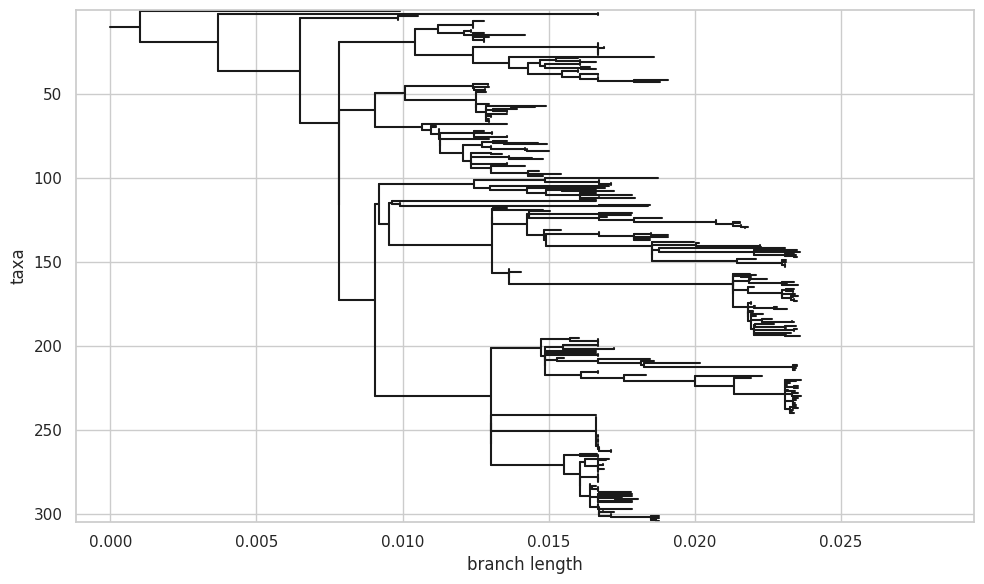

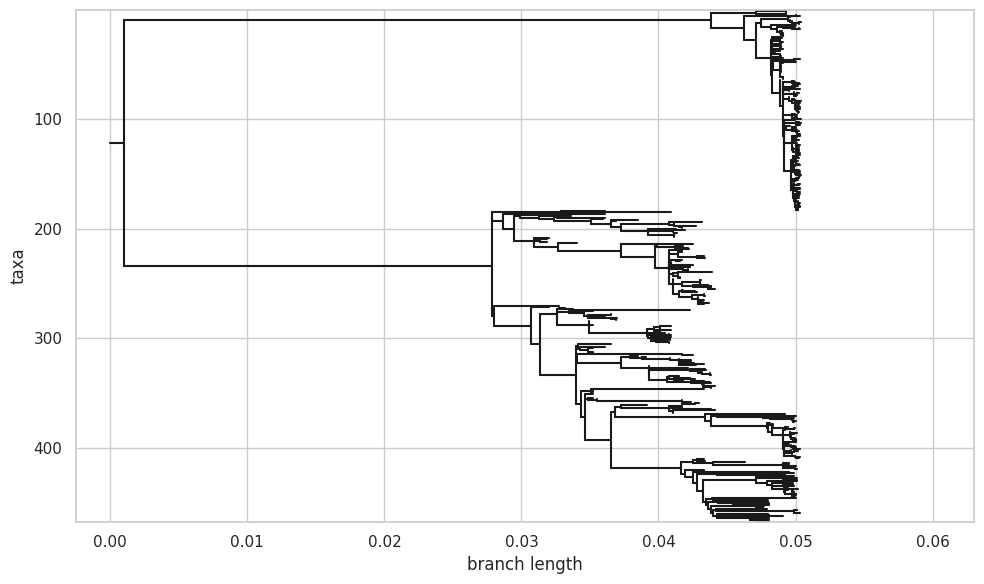

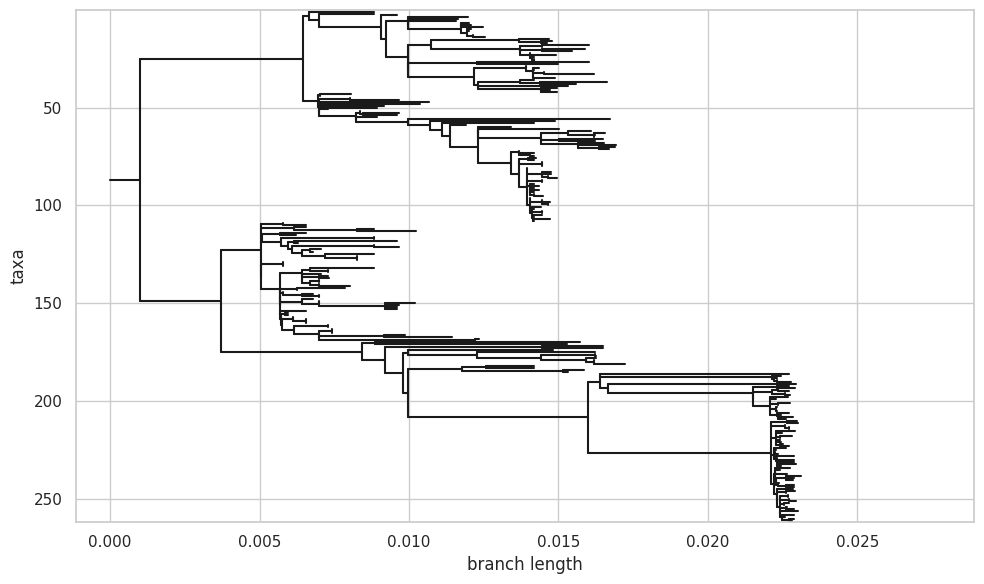

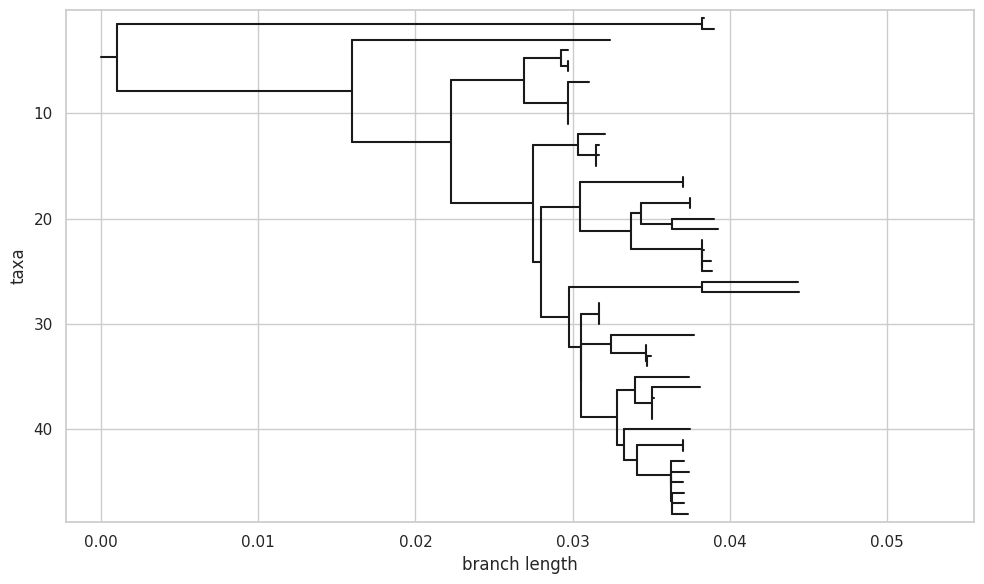

In [21]:
for i in range(4):
    sero = i+1
    tree = Phylo.read(TIME_TREE_COL.format(sero), "newick")
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    Phylo.draw(
        tree,
        axes=ax,
        label_func=lambda x: None,
        branch_labels=False,
        do_show=False
    )
    
    plt.tight_layout()
    #plt.savefig("phylogenetic_tree.png", dpi=300)
    plt.show()

## Transtale from refined tree using Augur

In [22]:
for i in range(4):
    sero = i+1
    print(f"Translating DENV{sero}")
    
    augur_translate(
        in_tree=TIME_TREE_COL.format(sero),
        ancestral_seqs=ANCESTRAL_NODE_COL.format(sero),
        ref_seq=TMP_GFF_COL.format(serotype),
        genes=["E"],
        out_node=NODE_AA_COL.format(sero),
        out_aln=AA_SEQS_COL.format(sero)
    )

Translating DENV1


Read in 2 features from reference sequence file
Validating schema of '../resources/colombia_data_1/ancestral/E_DENV1_ancestral.json'...
Validating schema of '../resources/colombia_data_1/AA_sequences/E_DENV1_aa.json'...
amino acid mutations written to ../resources/colombia_data_1/AA_sequences/E_DENV1_aa.json


Translating DENV2


Read in 2 features from reference sequence file
Validating schema of '../resources/colombia_data_1/ancestral/E_DENV2_ancestral.json'...
Validating schema of '../resources/colombia_data_1/AA_sequences/E_DENV2_aa.json'...
amino acid mutations written to ../resources/colombia_data_1/AA_sequences/E_DENV2_aa.json


Translating DENV3


Read in 2 features from reference sequence file
Validating schema of '../resources/colombia_data_1/ancestral/E_DENV3_ancestral.json'...
Validating schema of '../resources/colombia_data_1/AA_sequences/E_DENV3_aa.json'...
amino acid mutations written to ../resources/colombia_data_1/AA_sequences/E_DENV3_aa.json


Translating DENV4


Read in 2 features from reference sequence file
Validating schema of '../resources/colombia_data_1/ancestral/E_DENV4_ancestral.json'...
Validating schema of '../resources/colombia_data_1/AA_sequences/E_DENV4_aa.json'...
amino acid mutations written to ../resources/colombia_data_1/AA_sequences/E_DENV4_aa.json


## Sequence Count

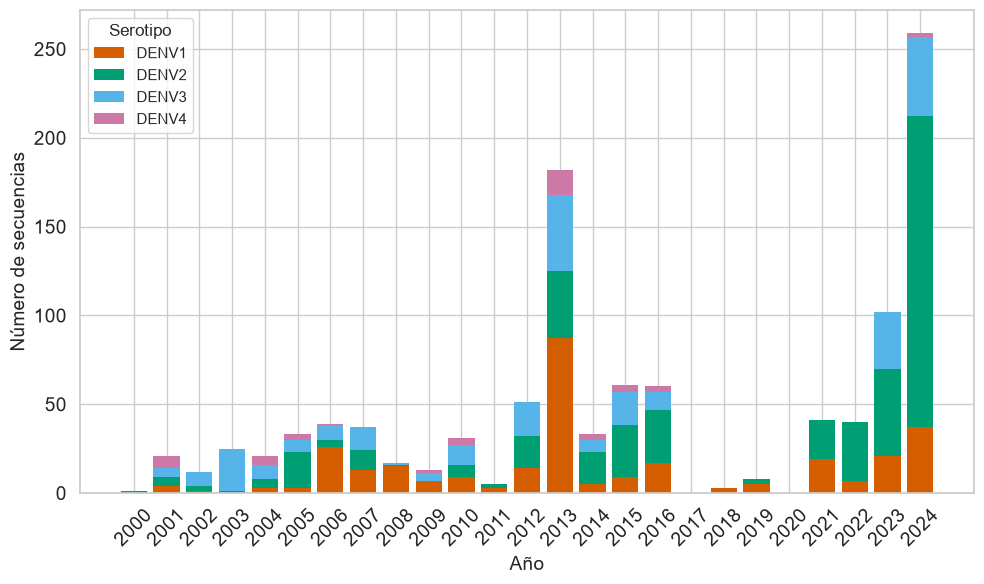

In [34]:
plot_data = []
all_years = None

for i in range(4):
    sero = i+1
    
    df = pd.read_csv(META_CLEAN_COL.format(sero), sep="\t")
    df["date"] = pd.to_datetime(df["date"], format="mixed", errors="coerce")
    df = df.dropna(subset=["date"])
    df["year"] = df["date"].dt.year
    
    counts = df.groupby("year").size()

    if all_years is None:
        all_years = range(counts.index.min(), counts.index.max() + 1)
    else:
        all_years = range(min(all_years[0], counts.index.min()), 
                         max(all_years[-1], counts.index.max()) + 1)
    

    counts = counts.reindex(all_years, fill_value=0).reset_index()
    counts.columns = ["year", "count"]
    counts["serotype"] = f"DENV{sero}"
    plot_data.append(counts)

plot_df = pd.concat(plot_data, ignore_index=True)

plot_pivot = plot_df.pivot(
    index="year",
    columns="serotype",
    values="count"
).fillna(0)

plt.figure(figsize=(10, 6))

colors = [SERO_COLORS[i] for i in range(1, 5)]

bottom = np.zeros(len(plot_pivot))

for serotype, color in zip(plot_pivot.columns, colors):
    plt.bar(
        plot_pivot.index,
        plot_pivot[serotype],
        bottom=bottom,
        label=serotype,
        color=color,
        linewidth=0
    )
    bottom += plot_pivot[serotype].values

plt.xlabel("Año", fontsize=14)
plt.ylabel("Número de secuencias", fontsize=14)
'''
plt.title(
    "Distribución temporal de las secuencias de Colombia del gen E",
    fontsize=14,
    fontweight="bold"
)
'''
plt.legend(title="Serotipo")
plt.xticks(plot_pivot.index, rotation=45, fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.savefig("../figures/distribucion_temporal_colombia.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [10]:
total_by_year = (
    plot_df
    .groupby("year", as_index=False)["count"]
    .sum()
    .rename(columns={"count": "total_sequences"})
)

total_by_year

,year,total_sequences
0,2000,1
1,2001,21
2,2002,12
3,2003,25
4,2004,21
5,2005,33
6,2006,39
7,2007,37
8,2008,17
9,2009,13


# Experimental (Antigenic Map) Data

## Split Original FASTA

In [51]:
out_handles = {i: open(IN_SEQS_EXP.format(i), "w") for i in range(1, 5)}

try:
    for record in SeqIO.parse(IN_COMB_EXP, "fasta"):
        sero_name = record.id.split("/")[0]
        
        if sero_name.startswith("DENV"):
            try:
                sero_num = int(sero_name.replace("DENV", ""))
                if sero_num in out_handles:
                    record.description = "" 
                    SeqIO.write(record, out_handles[sero_num], "fasta")
            except ValueError:
                print(f"  Warning: Could not parse serotype number from {record.id}")
finally:
    for h in out_handles.values():
        h.close()
        
print("  Finished splitting FASTA files.\n")

  Finished splitting FASTA files.



## Align sequences

In [52]:
for i in range(4):
    print(f"Aligning DENV{i+1}")
    serotype = i + 1
    augur_align(
        in_seqs=IN_SEQS_EXP.format(serotype),
        ref_seq=REF_SEQ.format(serotype),
        out_aln=ALN_SEQS_EXP.format(serotype),
        fill_gaps=True,
        nthreads="auto"
    )

Aligning DENV1

using mafft to align via:
	mafft --reorder --anysymbol --nomemsave --adjustdirection --thread 16 ../resources/experimental_data/aligned/align_DENV1.fasta.to_align.fasta 1> ../resources/experimental_data/aligned/align_DENV1.fasta 2> ../resources/experimental_data/aligned/align_DENV1.fasta.log 

	Katoh et al, Nucleic Acid Research, vol 30, issue 14
	https://doi.org/10.1093%2Fnar%2Fgkf436

No gaps in alignment to trim (with respect to the reference, NC_001477.1)
Aligning DENV2

using mafft to align via:
	mafft --reorder --anysymbol --nomemsave --adjustdirection --thread 16 ../resources/experimental_data/aligned/align_DENV2.fasta.to_align.fasta 1> ../resources/experimental_data/aligned/align_DENV2.fasta 2> ../resources/experimental_data/aligned/align_DENV2.fasta.log 

	Katoh et al, Nucleic Acid Research, vol 30, issue 14
	https://doi.org/10.1093%2Fnar%2Fgkf436

No gaps in alignment to trim (with respect to the reference, NC_001474.2)
Aligning DENV3

using mafft to align via

## Crop Aligments Gen E

In [53]:
for i in range(4):
    print(f"Crop DENV{i+1}")
    serotype = i + 1
    db = [db_denv1, db_denv2, db_denv3, db_denv4][i]
    e_start, e_end, strand = get_feature_coords(db, "envelope protein E")
    cropped_records = []
    
    for j, record in enumerate(SeqIO.parse(ALN_SEQS_EXP.format(serotype), "fasta")):
        
        if j == 0:
            continue
            
        if len(record.seq) < e_end:
            continue
        
        cropped_seq = record.seq[e_start-1:e_end]
        
        record.seq = cropped_seq

        new_id = record.id.split("|")[0]
        
        record.id = new_id
        record.name = new_id
        record.description = new_id
        
        cropped_records.append(record)
    
    SeqIO.write(
        cropped_records,
        CROP_SEQS_EXP.format(serotype),
        "fasta"
    )


Crop DENV1
Crop DENV2
Crop DENV3
Crop DENV4


## Create Metadata

In [54]:
for i in range(4):
    sero_num = i + 1
    crop_fasta = CROP_SEQS_EXP.format(sero_num)
    meta_path = META_EXP.format(sero_num)

    print(f"Step 2: Processing DENV{sero_num} Metadata")

    meta_rows = []

    for record in SeqIO.parse(crop_fasta, "fasta"):
        parts = record.id.split("/")
        
        if len(parts) < 3:
            print(f"  Warning: Skipping {record.id}, not enough fields.")
            continue

        strain_name = record.id
        country = parts[1]
        year = parts[2]

        date_str = f"{year}-01-01" if year.isdigit() and len(year) == 4 else None

        meta_rows.append({
            "strain": strain_name,
            "date": date_str,
            "country": country,
            "genotype": parts[0],
            "accession": parts[3] if len(parts) > 3 else ".",
            "extra": parts[4] if len(parts) > 4 else "."
        })

    meta_df = pd.DataFrame(meta_rows)
    
    required_cols = ["strain", "date", "country"]
    missing_cols = [c for c in required_cols if c not in meta_df.columns]
    if missing_cols:
        raise ValueError(f"DENV{sero_num}: Missing required metadata columns: {missing_cols}")

    before_filter = len(meta_df)
    meta_df = meta_df.dropna(subset=["date"])
    print(f"  Meta {len(meta_df)}/{before_filter} strains retained with valid dates.")

    meta_df.to_csv(meta_path, sep="\t", index=False)
    print(f"  Saved: {meta_path}\n")

Step 2: Processing DENV1 Metadata
  Meta 683/683 strains retained with valid dates.
  Saved: ../resources/experimental_data/metadata/E_DENV1_meta.tsv

Step 2: Processing DENV2 Metadata
  Meta 456/456 strains retained with valid dates.
  Saved: ../resources/experimental_data/metadata/E_DENV2_meta.tsv

Step 2: Processing DENV3 Metadata
  Meta 472/472 strains retained with valid dates.
  Saved: ../resources/experimental_data/metadata/E_DENV3_meta.tsv

Step 2: Processing DENV4 Metadata
  Meta 394/394 strains retained with valid dates.
  Saved: ../resources/experimental_data/metadata/E_DENV4_meta.tsv



## Create temp GFF

In [55]:
for i in range(4):
    print(f"Create temporal GFF DENV{i+1}")
    serotype = i + 1
    
    first_record = next(SeqIO.parse(CROP_SEQS_EXP.format(serotype), "fasta"))
    gene_length = len(first_record.seq)
    seqid = first_record.id
    
    with open(TMP_GFF_EXP.format(serotype), "w") as gff:
        gff.write("##gff-version 3\n")
        
        gff.write(
            f"{seqid}\t.\tsource\t1\t{gene_length}\t.\t+\t.\tID=nuc\n"
        )
        
        gff.write(
            f"{seqid}\t.\tgene\t1\t{gene_length}\t.\t+\t.\tID=E;Name=E;gene=E\n"
        )


Create temporal GFF DENV1
Create temporal GFF DENV2
Create temporal GFF DENV3
Create temporal GFF DENV4


## Tree Augur Workflow

In [56]:
for i in range(4):
    print(f"Building Tree DENV{i+1}")
    serotype = i + 1
    
    augur_tree(in_seqs=CROP_SEQS_EXP.format(serotype),
               out_tree=TREE_EXP.format(serotype))
    
    augur_refine(in_tree=TREE_EXP.format(serotype),
                 in_seqs=CROP_SEQS_EXP.format(serotype),
                 in_meta=META_EXP.format(serotype),
                 out_tree=TIME_TREE_EXP.format(serotype),
                 out_node=NODE_TREE_EXP.format(serotype))
    
    augur_ancestral(
        in_tree=TIME_TREE_EXP.format(serotype),
        in_seqs=CROP_SEQS_EXP.format(serotype),
        out_node=ANCESTRAL_NODE_EXP.format(serotype),
        out_seqs=ANCESTRAL_SEQS_EXP.format(serotype),
    )

Building Tree DENV1
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/experimental_data/cropped/E_DENV1-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/experimental_data/cropped/E_DENV1-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 49.125861406326294 seconds
augur refine is using TreeTime version 0.11.4

0.28	TreeTime.reroot: with method or node: least-squares

0.28	TreeTime.reroot: rerooting will ignore covariance and shared ancestry.

0.62	TreeTime.reroot: with method or node: least-squares

0.62	TreeTime.reroot: rerooting will ignore covariance and shared ancestry.

2.58	TreeTime.reroot: with method or node: least-squares

2.58	TreeTime.reroot: rerooting will account for covariance and shared ancestry.

3.95	###TreeTime.run: INITIAL ROUND

7.83	TreeTime.reroot: with method or node: least-squares

7.84	TreeTime.reroot: rerooting wil

Validating schema of '../resources/experimental_data/ancestral/E_DENV1_ancestral.json'...



Inferred ancestral sequence states using TreeTime:
	Sagulenko et al. TreeTime: Maximum-likelihood phylodynamic analysis
	Virus Evolution, vol 4, https://academic.oup.com/ve/article/4/1/vex042/4794731

augur ancestral is using TreeTime version 0.11.4
ancestral mutations written to ../resources/experimental_data/ancestral/E_DENV1_ancestral.json
ancestral sequences FASTA written to ../resources/experimental_data/ancestral/E_DENV1_ancestral.fasta
Building Tree DENV2
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/experimental_data/cropped/E_DENV2-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/experimental_data/cropped/E_DENV2-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 46.48673367500305 seconds
augur refine is using TreeTime version 0.11.4

0.22	TreeTime.reroot: with method or node: least-squares

0.22	TreeTime.reroot: rerooting wil

Validating schema of '../resources/experimental_data/ancestral/E_DENV2_ancestral.json'...



Inferred ancestral sequence states using TreeTime:
	Sagulenko et al. TreeTime: Maximum-likelihood phylodynamic analysis
	Virus Evolution, vol 4, https://academic.oup.com/ve/article/4/1/vex042/4794731

augur ancestral is using TreeTime version 0.11.4
ancestral mutations written to ../resources/experimental_data/ancestral/E_DENV2_ancestral.json
ancestral sequences FASTA written to ../resources/experimental_data/ancestral/E_DENV2_ancestral.fasta
Building Tree DENV3
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/experimental_data/cropped/E_DENV3-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/experimental_data/cropped/E_DENV3-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 50.76099419593811 seconds
augur refine is using TreeTime version 0.11.4

0.23	TreeTime.reroot: with method or node: least-squares

0.23	TreeTime.reroot: rerooting wil

Validating schema of '../resources/experimental_data/ancestral/E_DENV3_ancestral.json'...



Inferred ancestral sequence states using TreeTime:
	Sagulenko et al. TreeTime: Maximum-likelihood phylodynamic analysis
	Virus Evolution, vol 4, https://academic.oup.com/ve/article/4/1/vex042/4794731

augur ancestral is using TreeTime version 0.11.4
ancestral mutations written to ../resources/experimental_data/ancestral/E_DENV3_ancestral.json
ancestral sequences FASTA written to ../resources/experimental_data/ancestral/E_DENV3_ancestral.fasta
Building Tree DENV4
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/experimental_data/cropped/E_DENV4-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/experimental_data/cropped/E_DENV4-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 52.882771015167236 seconds
augur refine is using TreeTime version 0.11.4

0.21	TreeTime.reroot: with method or node: least-squares

0.21	TreeTime.reroot: rerooting wi

Validating schema of '../resources/experimental_data/ancestral/E_DENV4_ancestral.json'...


### Tree Plots

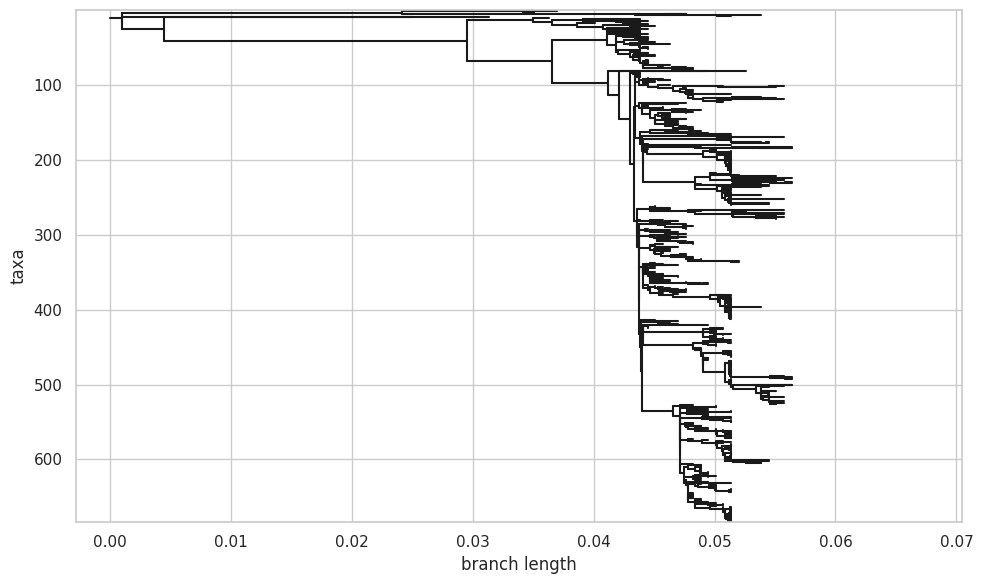

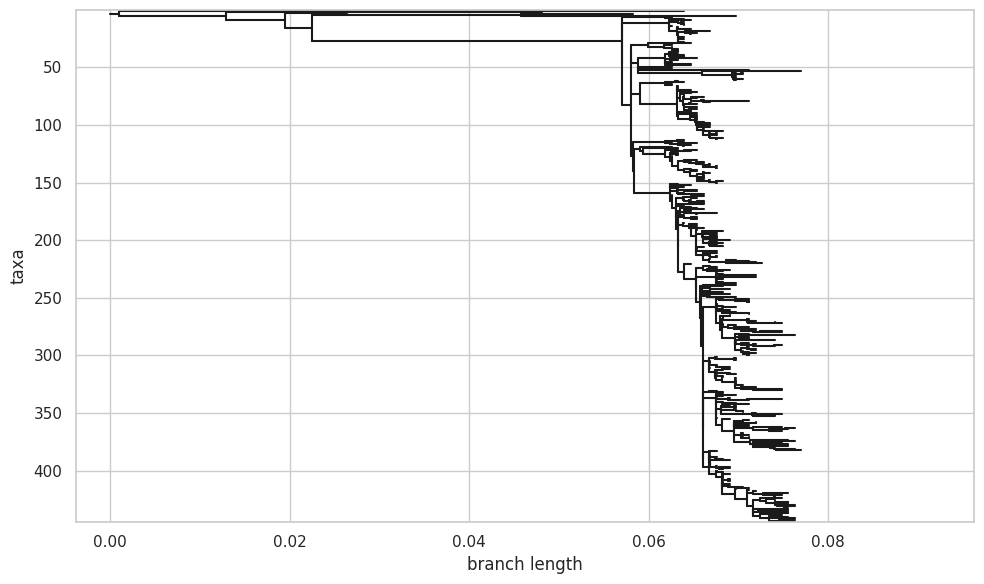

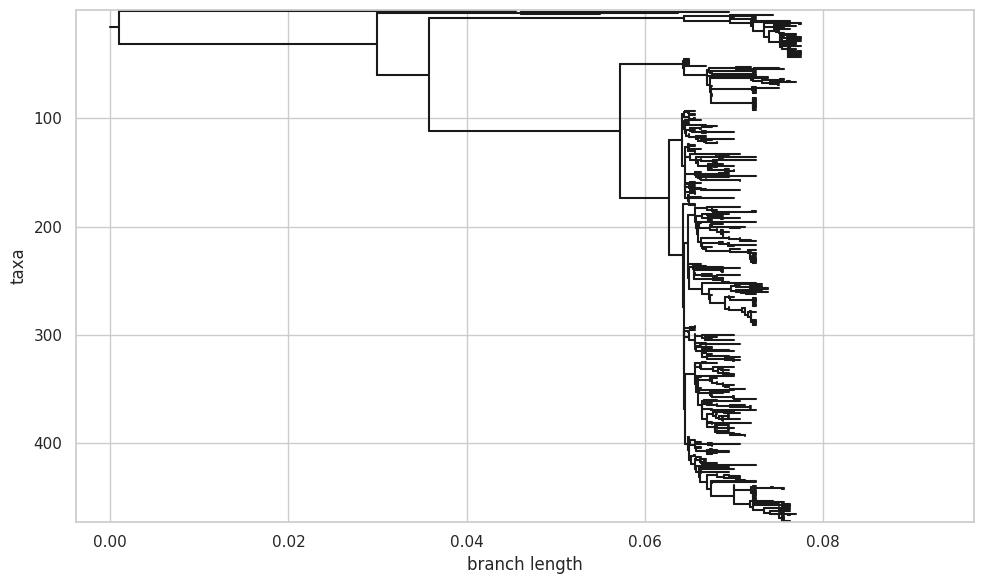

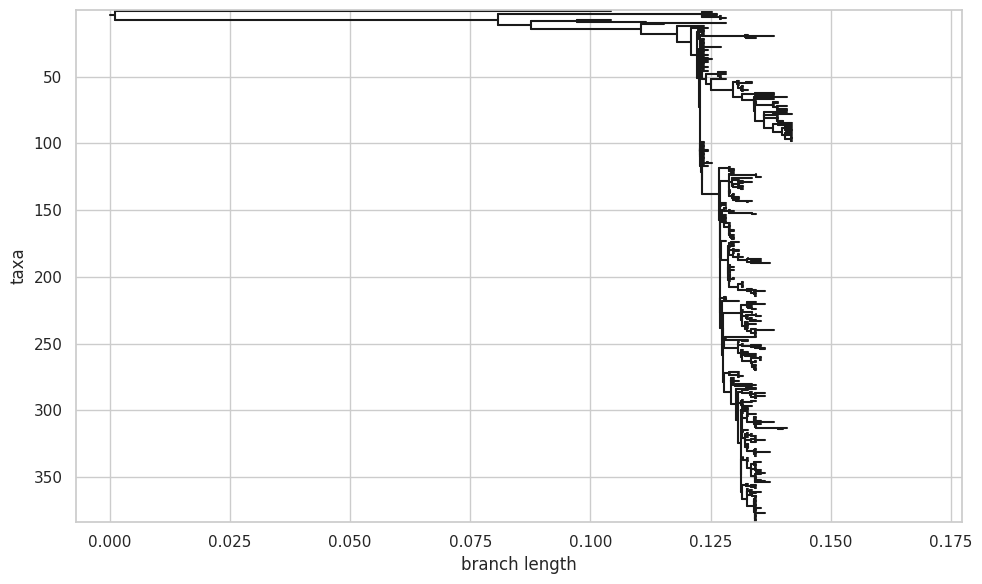

In [57]:
for i in range(4):
    sero = i+1
    tree = Phylo.read(TIME_TREE_EXP.format(sero), "newick")
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    Phylo.draw(
        tree,
        axes=ax,
        label_func=lambda x: None,
        branch_labels=False,
        do_show=False
    )
    
    plt.tight_layout()
    #plt.savefig("phylogenetic_tree.png", dpi=300)
    plt.show()

## Translate from refined tree using Augur

In [58]:
for i in range(4):
    sero = i+1
    print(f"Translating DENV{sero}")
    
    augur_translate(
        in_tree=TIME_TREE_EXP.format(sero),
        ancestral_seqs=ANCESTRAL_NODE_EXP.format(sero),
        ref_seq=TMP_GFF_EXP.format(serotype),
        genes=["E"],
        out_node=NODE_AA_EXP.format(sero),
        out_aln=AA_SEQS_EXP.format(sero)
    )

Translating DENV1


Read in 2 features from reference sequence file
Validating schema of '../resources/experimental_data/ancestral/E_DENV1_ancestral.json'...
Validating schema of '../resources/experimental_data/AA_sequences/E_DENV1_aa.json'...
amino acid mutations written to ../resources/experimental_data/AA_sequences/E_DENV1_aa.json


Translating DENV2


Read in 2 features from reference sequence file
Validating schema of '../resources/experimental_data/ancestral/E_DENV2_ancestral.json'...
Validating schema of '../resources/experimental_data/AA_sequences/E_DENV2_aa.json'...
amino acid mutations written to ../resources/experimental_data/AA_sequences/E_DENV2_aa.json


Translating DENV3


Read in 2 features from reference sequence file
Validating schema of '../resources/experimental_data/ancestral/E_DENV3_ancestral.json'...
Validating schema of '../resources/experimental_data/AA_sequences/E_DENV3_aa.json'...
amino acid mutations written to ../resources/experimental_data/AA_sequences/E_DENV3_aa.json


Translating DENV4


Read in 2 features from reference sequence file
Validating schema of '../resources/experimental_data/ancestral/E_DENV4_ancestral.json'...
Validating schema of '../resources/experimental_data/AA_sequences/E_DENV4_aa.json'...
amino acid mutations written to ../resources/experimental_data/AA_sequences/E_DENV4_aa.json


## Sequence Count

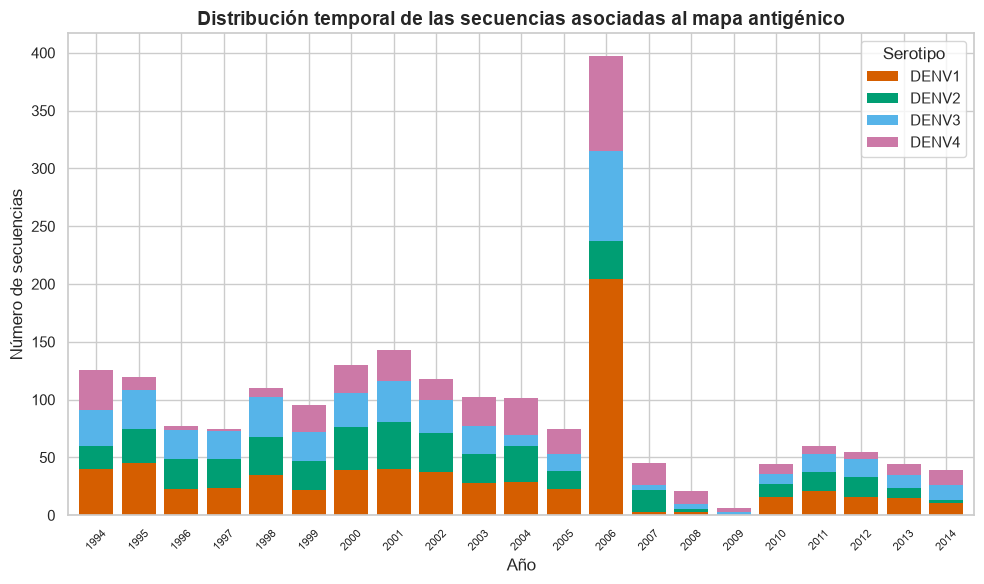

In [15]:
plot_data = []
all_years = None

for sero in range(1, 5):
    df = pd.read_csv(META_EXP.format(sero), sep="\t")
    df["date"] = pd.to_datetime(df["date"], format="mixed", errors="coerce")
    df = df.dropna(subset=["date"])
    df["year"] = df["date"].dt.year

    counts = df.groupby("year").size()

    if all_years is None:
        all_years = range(
            counts.index.min(),
            counts.index.max() + 1
        )
    else:
        all_years = range(
            min(all_years[0], counts.index.min()),
            max(all_years[-1], counts.index.max()) + 1
        )

    counts = counts.reindex(all_years, fill_value=0).reset_index()
    counts.columns = ["year", "count"]
    counts["serotype"] = f"DENV{sero}"
    plot_data.append(counts)

plot_df = pd.concat(plot_data, ignore_index=True)

# Formato para stacked barplot
plot_pivot = plot_df.pivot(
    index="year",
    columns="serotype",
    values="count"
).fillna(0)
plot_pivot = plot_pivot.loc[1994:2014]
fig, ax = plt.subplots(figsize=(10, 6))

plot_pivot.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=[SERO_COLORS[i] for i in range(1, 5)],
    width=0.8,
    linewidth=0
)

ax.set_xlabel("Año", fontsize=12)
ax.set_ylabel("Número de secuencias", fontsize=12)
ax.set_title(
    "Distribución temporal de las secuencias asociadas al mapa antigénico",
    fontsize=14,
    fontweight="bold"
)

ax.legend(title="Serotipo")
ax.tick_params(axis="x", rotation=45, labelsize=8)

plt.tight_layout()
plt.show()

# Merged Data

In [32]:
def merge_fastas(f1, f2, out):
    Path(out).parent.mkdir(parents=True, exist_ok=True)
    seen_ids = set()
    with open(out, "w") as out_f:
        for src, suffix in [(f1, "_COL"), (f2, "_EXP")]:
            with open(src, "r") as in_f:
                current_id = None
                for line in in_f:
                    if line.startswith(">"):
                        current_id = line[1:].strip().split()[0]
                        if current_id in seen_ids:
                            current_id = f"{current_id}{suffix}"
                            line = f">{current_id}\n"
                        seen_ids.add(current_id)
                    out_f.write(line)
    print(f"FASTA → {out}")

def merge_tsvs(f1, f2, out):
    Path(out).parent.mkdir(parents=True, exist_ok=True)
    header = None
    with open(out, "w") as out_f:
        for src in (f1, f2):
            with open(src, "r") as in_f:
                for line in in_f:
                    stripped = line.strip()
                    # Preserve comments & empty lines
                    if stripped.startswith("#") or stripped == "":
                        out_f.write(line)
                        continue
                    # First non-comment line = header
                    if header is None:
                        header = stripped
                        out_f.write(line)
                    # Skip duplicate headers, write data
                    elif stripped != header:
                        out_f.write(line)
    print(f"TSV  → {out}")

def merge_gffs(f1, f2, out):
    """Merges GFF3 files, ensures ##gff-version appears only once at top."""
    Path(out).parent.mkdir(parents=True, exist_ok=True)
    version_written = False
    with open(out, "w") as out_f:
        for src in (f1, f2):
            with open(src, "r") as in_f:
                for line in in_f:
                    stripped = line.strip()
                    if stripped.startswith("##gff-version"):
                        if not version_written:
                            out_f.write(line)
                            version_written = True
                        continue
                    out_f.write(line)
    print(f"GFF  → {out}")


SEROTYPES = [1, 2, 3, 4]

for sero in SEROTYPES:
    print(f"\n🔹 Processing DENV-{sero}...")
    merge_fastas(
        CROP_SEQS_COL.format(sero),
        CROP_SEQS_EXP.format(sero),
        CROP_SEQS_MERGE.format(sero)
    )
    merge_tsvs(
        META_CLEAN_COL.format(sero),
        META_EXP.format(sero),
        META_MERGE.format(sero)
    )
    # NO fusionar los GFF: cada uno trae su propio seqid y el resultado tiene
    # dos, lo que augur translate rechaza ("contains multiple seqids").
    # El GFF de merged se regenera desde el alineamiento merged en la celda
    # "Regenerar GFF temporal de merged", mas abajo.
    # merge_gffs(
    #     TMP_GFF_COL.format(sero),
    #     TMP_GFF_EXP.format(sero),
    #     TMP_GFF_MERGE.format(sero)
    # )

print("All merges complete.")


🔹 Processing DENV-1...
FASTA → ../resources/merged_data/cropped/align_DENV1.fasta
TSV  → ../resources/merged_data/metadata/merged_DENV1_meta.tsv
GFF  → ../resources/merged_data/tmp/E_DENV1.gff

🔹 Processing DENV-2...
FASTA → ../resources/merged_data/cropped/align_DENV2.fasta
TSV  → ../resources/merged_data/metadata/merged_DENV2_meta.tsv
GFF  → ../resources/merged_data/tmp/E_DENV2.gff

🔹 Processing DENV-3...
FASTA → ../resources/merged_data/cropped/align_DENV3.fasta
TSV  → ../resources/merged_data/metadata/merged_DENV3_meta.tsv
GFF  → ../resources/merged_data/tmp/E_DENV3.gff

🔹 Processing DENV-4...
FASTA → ../resources/merged_data/cropped/align_DENV4.fasta
TSV  → ../resources/merged_data/metadata/merged_DENV4_meta.tsv
GFF  → ../resources/merged_data/tmp/E_DENV4.gff
All merges complete.


## Tree Augur Workflow

In [33]:
for i in range(4):
    print(f"Building Tree DENV{i+1}")
    serotype = i + 1
    
    augur_tree(in_seqs=CROP_SEQS_MERGE.format(serotype),
               out_tree=TREE_MERGE.format(serotype))
    
    augur_refine(in_tree=TREE_MERGE.format(serotype),
                 in_seqs=CROP_SEQS_MERGE.format(serotype),
                 in_meta=META_MERGE.format(serotype),
                 out_tree=TIME_TREE_MERGE.format(serotype),
                 out_node=NODE_TREE_MERGE.format(serotype))
    
    augur_ancestral(
        in_tree=TIME_TREE_MERGE.format(serotype),
        in_seqs=CROP_SEQS_MERGE.format(serotype),
        out_node=ANCESTRAL_NODE_MERGE.format(serotype),
        out_seqs=ANCESTRAL_SEQS_MERGE.format(serotype),
    )

Building Tree DENV1
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/merged_data/cropped/align_DENV1-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/merged_data/cropped/align_DENV1-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 50.45821285247803 seconds
augur refine is using TreeTime version 0.11.4

0.39	TreeTime.reroot: with method or node: least-squares

0.39	TreeTime.reroot: rerooting will ignore covariance and shared ancestry.

0.90	TreeTime.reroot: with method or node: least-squares

0.90	TreeTime.reroot: rerooting will ignore covariance and shared ancestry.
pruning leaf  hDenV1/Colombia/BOL-UEB-016/2019
pruning leaf  hDenV1/Colombia/BOL-UEB-016-1/2019
pruning leaf  hDenV1/Colombia/BOL-UEB-152/2019
pruning leaf  hDenV1/Colombia/BOL-UEB-152-1/2019

3.78	TreeTime.reroot: with method or node: least-squares

3.79	TreeTime.reroot: rer

Validating schema of '../resources/merged_data/ancestral/E_DENV1_ancestral.json'...



Inferred ancestral sequence states using TreeTime:
	Sagulenko et al. TreeTime: Maximum-likelihood phylodynamic analysis
	Virus Evolution, vol 4, https://academic.oup.com/ve/article/4/1/vex042/4794731

augur ancestral is using TreeTime version 0.11.4
ancestral mutations written to ../resources/merged_data/ancestral/E_DENV1_ancestral.json
ancestral sequences FASTA written to ../resources/merged_data/ancestral/E_DENV1_ancestral.fasta
Building Tree DENV2
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/merged_data/cropped/align_DENV2-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/merged_data/cropped/align_DENV2-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 51.38780879974365 seconds
augur refine is using TreeTime version 0.11.4

0.35	TreeTime.reroot: with method or node: least-squares

0.35	TreeTime.reroot: rerooting will ignore covaria

Validating schema of '../resources/merged_data/ancestral/E_DENV2_ancestral.json'...



Inferred ancestral sequence states using TreeTime:
	Sagulenko et al. TreeTime: Maximum-likelihood phylodynamic analysis
	Virus Evolution, vol 4, https://academic.oup.com/ve/article/4/1/vex042/4794731

augur ancestral is using TreeTime version 0.11.4
ancestral mutations written to ../resources/merged_data/ancestral/E_DENV2_ancestral.json
ancestral sequences FASTA written to ../resources/merged_data/ancestral/E_DENV2_ancestral.fasta
Building Tree DENV3
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/merged_data/cropped/align_DENV3-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/merged_data/cropped/align_DENV3-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 54.452250480651855 seconds
augur refine is using TreeTime version 0.11.4

0.29	TreeTime.reroot: with method or node: least-squares

0.30	TreeTime.reroot: rerooting will ignore covari

Validating schema of '../resources/merged_data/ancestral/E_DENV3_ancestral.json'...



Inferred ancestral sequence states using TreeTime:
	Sagulenko et al. TreeTime: Maximum-likelihood phylodynamic analysis
	Virus Evolution, vol 4, https://academic.oup.com/ve/article/4/1/vex042/4794731

augur ancestral is using TreeTime version 0.11.4
ancestral mutations written to ../resources/merged_data/ancestral/E_DENV3_ancestral.json
ancestral sequences FASTA written to ../resources/merged_data/ancestral/E_DENV3_ancestral.fasta
Building Tree DENV4
Building a tree via:
	iqtree3 --threads-max 16 -s ../resources/merged_data/cropped/align_DENV4-delim.fasta -m GTR+G --ninit 2 -n 2 --epsilon 0.05 -T AUTO --redo > ../resources/merged_data/cropped/align_DENV4-delim.iqtree.log
	Please use the corresponding citations according to
	https://iqtree.github.io/doc/Home#how-to-cite-iq-tree

Building original tree took 51.64712858200073 seconds
augur refine is using TreeTime version 0.11.4

0.21	TreeTime.reroot: with method or node: least-squares

0.21	TreeTime.reroot: rerooting will ignore covaria

Validating schema of '../resources/merged_data/ancestral/E_DENV4_ancestral.json'...


## Translate from refined tree using Augur

### Regenerar GFF temporal de merged (un solo seqid)

In [38]:
# El GFF de merged NO se puede construir fusionando los GFF de Colombia y
# experimental: cada uno trae su propio seqid y augur translate exige uno solo
# ("contains multiple seqids"). Ademas fusionarlos no tiene sentido, porque el
# GFF solo declara las coordenadas del gen E RELATIVAS al alineamiento, y las
# secuencias ya estan alineadas y recortadas: las coordenadas son identicas para
# todas. El seqid es solo una etiqueta.
# Por eso se regenera desde el alineamiento merged, igual que en Colombia y
# experimental, tomando el largo real por serotipo (DENV3 mide 1479, no 1485).

for i in range(4):
    sero = i + 1

    records = list(SeqIO.parse(CROP_SEQS_MERGE.format(sero), "fasta"))
    lengths = {len(r.seq) for r in records}
    if len(lengths) != 1:
        raise ValueError(
            f"DENV{sero}: el alineamiento tiene largos distintos {sorted(lengths)}; "
            "el GFF asume un alineamiento uniforme"
        )

    gene_length = lengths.pop()
    seqid = records[0].id

    if gene_length % 3 != 0:
        print(f"  DENV{sero}: ATENCION, largo {gene_length} no es multiplo de 3")

    with open(TMP_GFF_MERGE.format(sero), "w") as gff:
        gff.write("##gff-version 3\n")
        gff.write(f"{seqid}\t.\tsource\t1\t{gene_length}\t.\t+\t.\tID=nuc\n")
        gff.write(f"{seqid}\t.\tgene\t1\t{gene_length}\t.\t+\t.\tID=E;Name=E;gene=E\n")

    # Garantia explicita de lo que augur translate exige
    with open(TMP_GFF_MERGE.format(sero)) as fh:
        seqids = {ln.split("\t")[0] for ln in fh if ln.strip() and not ln.startswith("#")}
    assert len(seqids) == 1, f"DENV{sero}: {len(seqids)} seqids en el GFF"

    print(f"DENV{sero}: GFF regenerado | {len(records)} secuencias | "
          f"E = 1..{gene_length} | seqid = {seqid}")


DENV1: GFF regenerado | 991 secuencias | E = 1..1485 | seqid = hDenV1/Colombia/un-OUCRU-101/2013
DENV2: GFF regenerado | 931 secuencias | E = 1..1485 | seqid = hDenV2/Colombia/SAN-UIS-0000033/2016
DENV3: GFF regenerado | 736 secuencias | E = 1..1479 | seqid = hDenV3/Colombia/un-OUCRU-30121/2012
DENV4: GFF regenerado | 442 secuencias | E = 1..1485 | seqid = hDenV4/Colombia/un-OUCRU-401211/2013


In [40]:
for i in range(4):
    sero = i + 1
    print(f"Translating DENV{sero}")

    augur_translate(
        in_tree=TIME_TREE_MERGE.format(sero),
        ancestral_seqs=ANCESTRAL_NODE_MERGE.format(sero),
        ref_seq=TMP_GFF_MERGE.format(sero),
        genes=["E"],
        out_node=NODE_AA_MERGE.format(sero),
        out_aln=AA_SEQS_MERGE.format(sero),
    )


Translating DENV1


Read in 2 features from reference sequence file
Validating schema of '../resources/merged_data/ancestral/E_DENV1_ancestral.json'...
Validating schema of '../resources/merged_data/AA_sequences/E_DENV1_aa.json'...
amino acid mutations written to ../resources/merged_data/AA_sequences/E_DENV1_aa.json


Translating DENV2


Read in 2 features from reference sequence file
Validating schema of '../resources/merged_data/ancestral/E_DENV2_ancestral.json'...
Validating schema of '../resources/merged_data/AA_sequences/E_DENV2_aa.json'...
amino acid mutations written to ../resources/merged_data/AA_sequences/E_DENV2_aa.json


Translating DENV3


Read in 2 features from reference sequence file
Validating schema of '../resources/merged_data/ancestral/E_DENV3_ancestral.json'...
Validating schema of '../resources/merged_data/AA_sequences/E_DENV3_aa.json'...
amino acid mutations written to ../resources/merged_data/AA_sequences/E_DENV3_aa.json


Translating DENV4


Read in 2 features from reference sequence file
Validating schema of '../resources/merged_data/ancestral/E_DENV4_ancestral.json'...
Validating schema of '../resources/merged_data/AA_sequences/E_DENV4_aa.json'...
amino acid mutations written to ../resources/merged_data/AA_sequences/E_DENV4_aa.json


## Titer Model (Katzelnick): preparacion del input

Convierte `neutralization-titers.txt` al TSV de 5 columnas que espera
`augur titers`, resolviendo los nombres de suero contra las puntas del
arbol merged. Reporta en voz alta lo que descarta.

In [42]:
# ---------------------------------------------------------------------------
# Katzelnick neutralization titers -> formato de entrada de augur titers
#
# Formato que espera augur (augur/titer_model.py, TiterCollection.load_from_file):
#   TSV de 5 columnas, SIN encabezado:
#     [0] virus de prueba   [1] virus de referencia del suero
#     [2] id del suero      [3] id de la fuente        [4] titulo
#
# Censura: augur ya la maneja. "<10" -> 5.0 (umbral/2) y ">5120" -> 10240.
# Por eso NO pre-convertimos: pasamos el string crudo y dejamos que augur
# aplique su convencion. Es imputacion a la mitad del limite de deteccion:
# cruda y sesgada, pero es la convencion del modelo. Los "*" (sin medir)
# los descartamos aqui para que queden en el conteo.
# ---------------------------------------------------------------------------

SRC_ID = "katzelnick2015"

# Sueros cuyo virus de referencia no resuelve por coincidencia automatica
# pero si se identifico manualmente contra las puntas del arbol merged.
# Ojo: el ano del nombre del suero puede ser el de extraccion del suero, no el
# del virus (SENDAK dice 2003 y el virus es de 1970).
SERA_MANUAL = {
    "DEN1_NAURU_1974_NIHVACCINE":       "DENV1/NAURU/1974/RDENV1-WP-1A",
    "DEN2_TONGA_1974_NIHVACCINE":       "DENV2/TONGA/1974/TONGA-74",
    "DEN3_FIJI_1992__":                 "DENV3/FIJI/1992/29472-L11422-I",
    "DEN4_INDONESIA_1973_M30153_P5":    "DENV4/INDONESIA/1973/M30153-AC36",
    "DEN2_SENEGAL_2003_SENDAK_HD_0674": "DENV2/SENEGAL/1970/SENDAK-HD-10674",
}

# Sueros descartados: su virus de referencia NO esta en
# full-genome-only-sequences.fasta, asi que no puede ser punta del arbol.
# Recuperarlos exige bajar esas secuencias de GenBank.
SERA_ABSENT = {
    "DEN2_CAMBODIA_2009_D2T0601085_KH09_KSP",
    "DEN2_VIETNAM_2006_BID_V735",
    "DEN2_VIETNAM_2003_DF_670",
    "DEN3_CAMBODIA_2011_V0907330",
    "DEN3_NICARAGUA_2009_608",
    "DEN4_CAMBODIA_2010_U0811386",
    "DEN4_CAMBODIA_2011_V0624301",
}


def load_tips(fasta_path):
    """Nombres de punta de un alineamiento (lo que augur vera en el arbol)."""
    tips = set()
    with open(fasta_path) as fh:
        for line in fh:
            if line.startswith(">"):
                tips.add(line[1:].strip().split()[0])
    return tips


def _norm_acc(text):
    """Normaliza un accession para comparar: mayusculas, sin GENBANK, solo alfanumerico."""
    return re.sub(r"[^A-Z0-9]", "", text.upper().replace("GENBANK", ""))


def map_sera_to_tips(sera_names, tips_by_sero, verbose=True):
    """Mapea nombres de columna de suero (DEN1_BURMA_2005_61117) a nombres de punta
    (DENV1/MYANMAR/2005/61117).

    El pais no sirve para emparejar (BURMA vs MYANMAR), asi que empareja por
    serotipo + ano + accession normalizado. Solo acepta coincidencias unicas.
    Devuelve (mapping, unresolved).
    """
    mapping, unresolved = {}, []

    for serum in sera_names:
        if serum in SERA_ABSENT:
            unresolved.append((serum, "virus de referencia ausente en los datos fuente"))
            continue
        if serum in SERA_MANUAL:
            tip = SERA_MANUAL[serum]
            sero = serum[3]
            if tip in tips_by_sero.get(sero, set()):
                mapping[serum] = tip
            else:
                unresolved.append((serum, f"alias manual '{tip}' no esta en el arbol"))
            continue

        m = re.match(r"DEN(\d)_(.+)$", serum)
        if not m:
            unresolved.append((serum, "nombre no parseable"))
            continue
        sero, rest = m.group(1), m.group(2)
        toks = rest.split("_")
        years = [i for i, t in enumerate(toks) if re.fullmatch(r"(19|20)\d\d", t)]
        if not years:
            unresolved.append((serum, "sin ano en el nombre"))
            continue
        yi = years[0]
        year, acc = toks[yi], _norm_acc("".join(toks[yi + 1:]))

        cands = []
        for tip in tips_by_sero.get(sero, set()):
            parts = tip.split("/")
            if len(parts) < 4 or parts[2] != year:
                continue
            tip_acc = _norm_acc("/".join(parts[3:]))
            if acc and (tip_acc == acc or tip_acc.startswith(acc) or acc.startswith(tip_acc)):
                cands.append(tip)

        if len(cands) == 1:
            mapping[serum] = cands[0]
        else:
            unresolved.append((serum, f"{len(cands)} candidatos: {sorted(cands)[:4]}"))

    if verbose:
        print(f"Sueros mapeados: {len(mapping)}/{len(sera_names)}")
        if unresolved:
            print(f"Sueros descartados: {len(unresolved)}")
            for serum, reason in unresolved:
                print(f"   - {serum:42s} {reason}")
    return mapping, unresolved


def build_titer_tsv(raw_path, tips_by_sero, serum_map, out_template, map_template):
    """Escribe un TSV de titulos por serotipo, solo con pares intra-serotipo
    donde el virus de prueba Y el virus de referencia del suero son puntas.

    Nota importante: como los arboles son por serotipo, TODAS las mediciones
    entre serotipos se descartan. Es la unica opcion coherente con un arbol por
    serotipo, y deja casi solo titulos homologos (altos), donde la censura casi
    no pesa. Pero significa que estos modelos no dicen nada sobre reactividad
    cruzada entre serotipos.
    """
    with open(raw_path) as fh:
        lines = [ln for ln in fh.read().splitlines() if ln.strip()]

    sera_cols = lines[0].split()
    rows = [ln.split() for ln in lines[1:]]

    stats = {}
    for sero in "1234":
        tips = tips_by_sero[sero]
        written = skipped_star = skipped_pair = censored = 0
        out_lines = []

        for row in rows:
            virus, values = row[0], row[1:]
            if virus not in tips:
                continue
            for serum, value in zip(sera_cols, values):
                ref = serum_map.get(serum)
                if ref is None or ref not in tips:
                    skipped_pair += 1
                    continue
                if value == "*":
                    skipped_star += 1
                    continue
                if value.startswith("<") or value.startswith(">"):
                    censored += 1
                out_lines.append(f"{virus}\t{ref}\t{serum}\t{SRC_ID}\t{value}")
                written += 1

        out_path = out_template.format(sero)
        with open(out_path, "w") as fh:
            fh.write("\n".join(out_lines) + ("\n" if out_lines else ""))

        sera_used = sorted({ln.split("\t")[2] for ln in out_lines})
        with open(map_template.format(sero), "w") as fh:
            fh.write("serum_id\tref_virus\n")
            for serum in sera_used:
                fh.write(f"{serum}\t{serum_map[serum]}\n")

        pct = 100.0 * censored / written if written else 0.0
        stats[sero] = dict(measurements=written, sera=len(sera_used),
                           censored=censored, pct_censored=pct,
                           skipped_star=skipped_star)
        print(f"DENV{sero}: {written:5d} mediciones | {len(sera_used)} sueros | "
              f"censuradas {censored} ({pct:.1f}%) | sin medir '*' {skipped_star} "
              f"-> {out_path}")

    return stats


In [43]:
tips_by_sero = {
    str(s): load_tips(CROP_SEQS_MERGE.format(s)) for s in range(1, 5)
}

with open(RAW_TITERS) as fh:
    sera_cols = fh.readline().split()

serum_map, serum_unresolved = map_sera_to_tips(sera_cols, tips_by_sero)

print()
titer_stats = build_titer_tsv(
    raw_path=RAW_TITERS,
    tips_by_sero=tips_by_sero,
    serum_map=serum_map,
    out_template=TITERS_MERGE,
    map_template=SERA_MAP_MERGE,
)


Sueros mapeados: 29/36
Sueros descartados: 7
   - DEN2_CAMBODIA_2009_D2T0601085_KH09_KSP     virus de referencia ausente en los datos fuente
   - DEN2_VIETNAM_2006_BID_V735                 virus de referencia ausente en los datos fuente
   - DEN3_CAMBODIA_2011_V0907330                virus de referencia ausente en los datos fuente
   - DEN4_CAMBODIA_2010_U0811386                virus de referencia ausente en los datos fuente
   - DEN4_CAMBODIA_2011_V0624301                virus de referencia ausente en los datos fuente
   - DEN2_VIETNAM_2003_DF_670                   virus de referencia ausente en los datos fuente
   - DEN3_NICARAGUA_2009_608                    virus de referencia ausente en los datos fuente

DENV1:   534 mediciones | 8 sueros | censuradas 9 (1.7%) | sin medir '*' 306 -> ../resources/merged_data/titers/titers_DENV1.tsv
DENV2:   348 mediciones | 9 sueros | censuradas 45 (12.9%) | sin medir '*' 516 -> ../resources/merged_data/titers/titers_DENV2.tsv
DENV3:   418 medicione

## Titer Models: `tree` y `sub`

In [44]:
for i in range(4):
    sero = i + 1
    print(f"\n=== Titer models DENV{sero} ===")

    # tree: reparte la caida de titulo entre RAMAS del arbol -> dTiter / cTiter
    augur_titers_tree(
        titers=TITERS_MERGE.format(sero),
        in_tree=TIME_TREE_MERGE.format(sero),
        out_model=TITER_TREE_MODEL_MERGE.format(sero),
    )

    # sub: la reparte entre SUSTITUCIONES de aminoacido -> dTiterSub / cTiterSub
    # Es el que transfiere senal a las secuencias colombianas sin titulos.
    augur_titers_sub(
        titers=TITERS_MERGE.format(sero),
        alignments=AA_SEQS_MERGE_E.format(sero),
        gene_names="E",
        in_tree=TIME_TREE_MERGE.format(sero),
        out_model=TITER_SUB_MODEL_MERGE.format(sero),
    )



=== Titer models DENV1 ===


Read titers from ../resources/merged_data/titers/titers_DENV1.tsv, found:
 --- 105 strains
 --- 1 data sources
 --- 534 total measurements


Normalized titers and restricted to measurements in list:
 - remaining data set
 --- 6  reference virues
 --- 6  sera
 --- 105  test_viruses
 --- 524  non-redundant test virus/serum pairs
Made training data as fraction 1.0 of all measurements
 - remaining data set
 --- 6  reference virues
 --- 6  sera
 --- 105  test_viruses
 --- 524  non-redundant test virus/serum pairs
 --- 524  measurements in training set
# of reference strains: 6
# of eligible branches with titer constraints 100
Found (524, 211) measurements x parameters
     pcost       dcost       gap    pres   dres
 0: -4.1400e+02 -3.3433e+02  4e+02  2e+01  3e-02
 1: -3.6980e+02 -3.8338e+02  9e+01  4e+00  6e-03
 2: -3.6955e+02 -3.7561e+02  2e+01  6e-01  1e-03
 3: -3.6963e+02 -3.7184e+02  3e+00  8e-02  1e-04
 4: -3.7058e+02 -3.7093e+02  4e-01  6e-03  9e-06
 5: -3.7078e+02 -3.7081e+02  3e-02  2e-04  3e-07
 6: -3.7080e+02 -3.7080e+02  1e-03  4e-06  6e-09
 7: -3.7080e+02 -3.7080e+02  4e-05  4e-08  6e-11
Optimal solution found.
rms d

Read titers from ../resources/merged_data/titers/titers_DENV1.tsv, found:
 --- 105 strains
 --- 1 data sources
 --- 534 total measurements


Normalized titers and restricted to measurements in list:
 - remaining data set
 --- 6  reference virues
 --- 6  sera
 --- 105  test_viruses
 --- 524  non-redundant test virus/serum pairs
Made training data as fraction 1.0 of all measurements
 - remaining data set
 --- 6  reference virues
 --- 6  sera
 --- 105  test_viruses
 --- 524  non-redundant test virus/serum pairs
 --- 524  measurements in training set
adding ('E', 'S155T') to cluster  [('E', 'D37N'), ('E', 'S155T')]
adding ('E', 'T155S') to cluster  [('E', 'N37D'), ('E', 'T155S')]
adding ('E', 'I161T') to cluster  [('E', 'N37D'), ('E', 'T155S'), ('E', 'I161T')]
adding ('E', 'I324V') to cluster  [('E', 'S8N'), ('E', 'I324V')]
adding ('E', 'V324I') to cluster  [('E', 'N8S'), ('E', 'V324I')]
adding ('E', 'I346T') to cluster  [('E', 'M83V'), ('E', 'I346T')]
adding ('E', 'L351V') to cluster  [('E', 'S225T'), ('E', 'L351V')]
adding ('E', 'A369T') to cluster  [('E', 'D37N'), ('E', 'S155T'), ('E', 'A369T')]
adding ('E', 'T369A') to clus

Read titers from ../resources/merged_data/titers/titers_DENV2.tsv, found:
 --- 96 strains
 --- 1 data sources
 --- 348 total measurements


... (7 outputs left out)

Read titers from ../resources/merged_data/titers/titers_DENV4.tsv, found:
 --- 102 strains
 --- 1 data sources
 --- 318 total measurements


Normalized titers and restricted to measurements in list:
 - remaining data set
 --- 4  reference virues
 --- 4  sera
 --- 100  test_viruses
 --- 305  non-redundant test virus/serum pairs
Made training data as fraction 1.0 of all measurements
 - remaining data set
 --- 4  reference virues
 --- 4  sera
 --- 100  test_viruses
 --- 305  non-redundant test virus/serum pairs
 --- 305  measurements in training set
# of reference strains: 4
# of eligible branches with titer constraints 97
Found (305, 201) measurements x parameters
     pcost       dcost       gap    pres   dres
 0: -2.3874e+02 -1.7392e+02  4e+02  2e+01  3e-02
 1: -2.0024e+02 -2.1873e+02  1e+02  5e+00  5e-03
 2: -2.0009e+02 -2.0968e+02  3e+01  1e+00  1e-03
 3: -2.0079e+02 -2.0491e+02  9e+00  3e-01  3e-04
 4: -2.0186e+02 -2.0270e+02  1e+00  2e-02  2e-05
 5: -2.0237e+02 -2.0246e+02  1e-01  1e-03  1e-06
 6: -2.0244e+02 -2.0244e+02  3e-03  1e-05  1e-08
 7: -2.0244e+02 -2.0244e+02  6e-05  1e-07  1e-10
 8: -2.0244e+02 -2.0244e+02  6

Read titers from ../resources/merged_data/titers/titers_DENV4.tsv, found:
 --- 102 strains
 --- 1 data sources
 --- 318 total measurements


Normalized titers and restricted to measurements in list:
 - remaining data set
 --- 4  reference virues
 --- 4  sera
 --- 100  test_viruses
 --- 305  non-redundant test virus/serum pairs
Made training data as fraction 1.0 of all measurements
 - remaining data set
 --- 4  reference virues
 --- 4  sera
 --- 100  test_viruses
 --- 305  non-redundant test virus/serum pairs
 --- 305  measurements in training set
adding ('E', 'I155T') to cluster  [('E', 'L120S'), ('E', 'I155T')]
adding ('E', 'T182S') to cluster  [('E', 'V4I'), ('E', 'T182S')]
adding ('E', 'K202E') to cluster  [('E', 'V4I'), ('E', 'T182S'), ('E', 'K202E')]
adding ('E', 'Y233H') to cluster  [('E', 'T46I'), ('E', 'Y233H')]
adding ('E', 'K310R') to cluster  [('E', 'V4I'), ('E', 'T182S'), ('E', 'K202E'), ('E', 'K310R')]
adding ('E', 'A329T') to cluster  [('E', 'T46I'), ('E', 'Y233H'), ('E', 'A329T')]
adding ('E', 'L357F') to cluster  [('E', 'V351I'), ('E', 'L357F')]
dimensions of old design matrix (305, 136)
dimensions of new de

## Analisis exploratorio de los modelos de titulos

1. COBERTURA DEL MODELO
         nodos  ramas dTiter>0  suma dTiter  max cTiter  subs != 0
DENV1     1882             100         4.38        0.65         12
DENV2     1795              94         5.29        1.38         10
DENV3     1422              72         7.15        2.43         10
DENV4      844              66         7.30        2.15          6

Si 'ramas dTiter>0' es muy bajo o 'suma dTiter' ~ 0, el modelo quedo
degenerado y lo que sigue no significa nada.

2. AVIDEZ: cota inferior del error al predecir un virus no medido
La avidez es un termino por virus. Para una secuencia colombiana sin
titulos augur la fija en 0, asi que la dispersion de las avideces
ajustadas acota el error de esas predicciones. En unidades log2.

        modelo     n      SD      p5     p95   ~veces
DENV1     tree   105    0.36   -0.60    0.47      1.3x
DENV1      sub   105    0.39   -0.66    0.55      1.3x
DENV2     tree    96    0.39   -0.72    0.63      1.3x
DENV2      sub    96    0.40   -0.79   

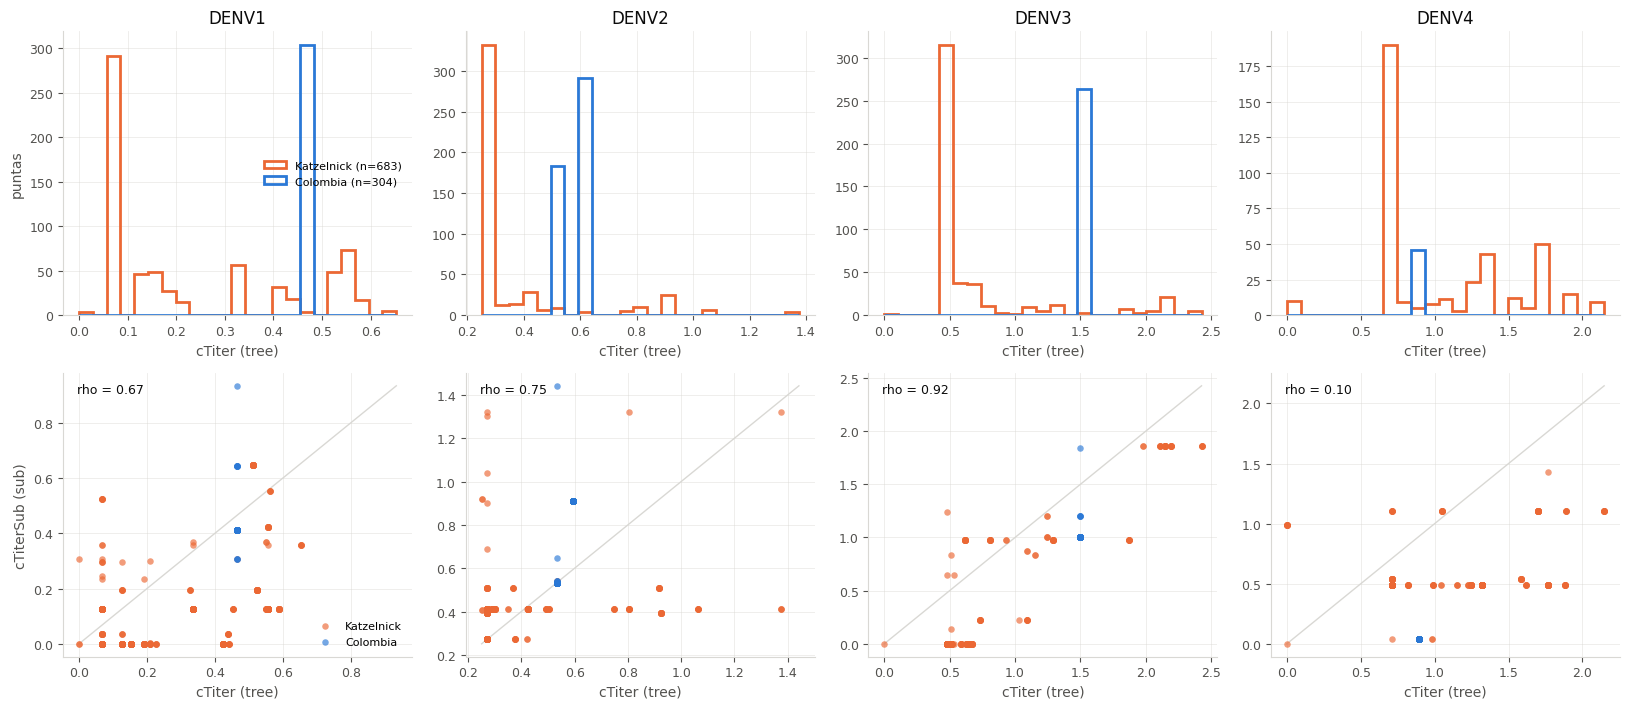

In [45]:
# ===========================================================================
# Analisis exploratorio de los modelos de titulos
#
# Estructura de los JSON que escribe augur (augur/titers.py):
#   tree -> titers, potency, avidity, nodes{name: dTiter, cTiter}
#   sub  -> titers, potency, avidity, substitution, nodes{name: dTiterSub, cTiterSub}
#
# Cinco preguntas, en orden de importancia para este proyecto:
#   1. Cobertura    - el modelo ajusto algo, o salio degenerado?
#   2. Avidez       - cuanto error arrastran las predicciones de virus no medidos?
#   3. Colombianas  - reciben senal antigenica real, o heredan la del ancestro?
#   4. tree vs sub  - coinciden los dos modelos? (el contraste independiente)
#   5. Sustituciones- que cambios cargan el peso?
# ===========================================================================

import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# Paleta: slots 1-2 de la paleta de referencia (validados en all-pairs).
C_COL = "#2a78d6"   # Colombia
C_REF = "#eb6834"   # Katzelnick (panel de referencia)
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"


def load_model(path):
    try:
        with open(path) as fh:
            return json.load(fh)
    except FileNotFoundError:
        return None


def numeric_leaves(obj):
    """potency / avidity pueden venir anidados. Devuelve solo los valores float."""
    out = []

    def walk(o):
        if isinstance(o, dict):
            for v in o.values():
                walk(v)
        elif isinstance(o, (int, float)) and not isinstance(o, bool):
            out.append(float(o))

    walk(obj)
    return out


def is_colombian(name):
    return "colombia" in name.lower()


# --------------------------------------------------------------- carga
models = {}
for sero in range(1, 5):
    tree = load_model(TITER_TREE_MODEL_MERGE.format(sero))
    sub = load_model(TITER_SUB_MODEL_MERGE.format(sero))
    if tree is None or sub is None:
        print(f"DENV{sero}: falta el JSON del modelo, lo salto")
        continue
    models[sero] = dict(tree=tree, sub=sub,
                        tips=load_tips(CROP_SEQS_MERGE.format(sero)))

if not models:
    raise SystemExit("No hay modelos cargados: corre primero las celdas de titer models")


# ------------------------------------------------- 1. cobertura del modelo
print("=" * 78)
print("1. COBERTURA DEL MODELO")
print("=" * 78)
print(f"{'':6s} {'nodos':>7s} {'ramas dTiter>0':>15s} {'suma dTiter':>12s} "
      f"{'max cTiter':>11s} {'subs != 0':>10s}")
for sero, m in models.items():
    nodes = m["tree"].get("nodes", {})
    dt = np.array([v.get("dTiter", 0.0) for v in nodes.values()])
    ct = np.array([v.get("cTiter", 0.0) for v in nodes.values()])
    subs = m["sub"].get("substitution", {}) or {}
    n_sub = sum(1 for v in numeric_leaves(subs) if abs(v) > 1e-9)
    print(f"DENV{sero}  {len(nodes):7d} {int((dt > 1e-9).sum()):15d} "
          f"{dt.sum():12.2f} {ct.max() if len(ct) else 0:11.2f} {n_sub:10d}")
print("\nSi 'ramas dTiter>0' es muy bajo o 'suma dTiter' ~ 0, el modelo quedo")
print("degenerado y lo que sigue no significa nada.")


# ----------------------------------------------------- 2. avidez (el limite)
print("\n" + "=" * 78)
print("2. AVIDEZ: cota inferior del error al predecir un virus no medido")
print("=" * 78)
print("La avidez es un termino por virus. Para una secuencia colombiana sin")
print("titulos augur la fija en 0, asi que la dispersion de las avideces")
print("ajustadas acota el error de esas predicciones. En unidades log2.\n")
print(f"{'':6s} {'modelo':>7s} {'n':>5s} {'SD':>7s} {'p5':>7s} {'p95':>7s} "
      f"{'~veces':>8s}")
for sero, m in models.items():
    for label, key in (("tree", "tree"), ("sub", "sub")):
        avi = np.array(numeric_leaves(m[key].get("avidity", {}) or {}))
        if avi.size == 0:
            print(f"DENV{sero}  {label:>7s} {'-':>5s}  (modelo sin avidez ajustada)")
            continue
        sd = avi.std(ddof=1) if avi.size > 1 else 0.0
        print(f"DENV{sero}  {label:>7s} {avi.size:5d} {sd:7.2f} "
              f"{np.percentile(avi, 5):7.2f} {np.percentile(avi, 95):7.2f} "
              f"{2 ** sd:8.1f}x")
print("\n'~veces' es 2^SD: el factor multiplicativo de error en el titulo.")
print("Si ronda 2x o mas, las predicciones celda-por-celda no son defendibles;")
print("habla de posicion antigenica relativa, no de titulos.")


# ------------------------------- 3. colombianas: senal real o heredada?
print("\n" + "=" * 78)
print("3. SECUENCIAS COLOMBIANAS: senal propia o heredada del ancestro?")
print("=" * 78)
print("Si muchas puntas colombianas comparten el mismo cTiter, es que cuelgan")
print("de ramas con dTiter=0 y heredan el valor del ancestro medido: eso es el")
print("prior del modelo, no un resultado.\n")
print(f"{'':6s} {'grupo':>12s} {'puntas':>7s} {'valores unicos':>15s} "
      f"{'mediana':>8s} {'rango':>16s} {'=0':>6s}")
eda_tips = {}
for sero, m in models.items():
    nodes = m["tree"].get("nodes", {})
    rows = {}
    for group, pred in (("Colombia", True), ("Katzelnick", False)):
        vals = np.array([nodes[t].get("cTiter", np.nan)
                         for t in m["tips"]
                         if t in nodes and is_colombian(t) == pred])
        vals = vals[~np.isnan(vals)]
        rows[group] = vals
        if vals.size == 0:
            print(f"DENV{sero}  {group:>12s} {0:7d}")
            continue
        uniq = len(np.unique(np.round(vals, 6)))
        print(f"DENV{sero}  {group:>12s} {vals.size:7d} "
              f"{uniq:7d} ({100.0 * uniq / vals.size:4.1f}%) "
              f"{np.median(vals):8.2f} "
              f"[{vals.min():6.2f},{vals.max():6.2f}] "
              f"{int((np.abs(vals) < 1e-9).sum()):6d}")
    eda_tips[sero] = rows


# ------------------------------------------------ 4. acuerdo tree vs sub
print("\n" + "=" * 78)
print("4. ACUERDO ENTRE tree Y sub (contraste independiente)")
print("=" * 78)
eda_pairs = {}
for sero, m in models.items():
    nt = m["tree"].get("nodes", {})
    ns = m["sub"].get("nodes", {})
    shared = [t for t in m["tips"] if t in nt and t in ns]
    x = np.array([nt[t].get("cTiter", np.nan) for t in shared])
    y = np.array([ns[t].get("cTiterSub", np.nan) for t in shared])
    ok = ~(np.isnan(x) | np.isnan(y))
    x, y = x[ok], y[ok]
    col = np.array([is_colombian(t) for t, k in zip(shared, ok) if k])
    eda_pairs[sero] = (x, y, col)
    if x.size < 3 or np.ptp(x) == 0 or np.ptp(y) == 0:
        print(f"DENV{sero}: datos insuficientes o sin varianza")
        continue
    rho, p = spearmanr(x, y)
    print(f"DENV{sero}: n={x.size:4d}  Spearman rho={rho:6.3f}  p={p:.2g}  "
          f"| cTiter {x.min():.2f}-{x.max():.2f}  "
          f"cTiterSub {y.min():.2f}-{y.max():.2f}")
print("\nrho alto = las dos rutas coinciden y el resultado es defendible.")
print("rho bajo = una de las dos esta extrapolando; mira cuales puntas discrepan.")


# ------------------------------------------------------- 5. sustituciones
print("\n" + "=" * 78)
print("5. SUSTITUCIONES CON MAYOR EFECTO (modelo sub)")
print("=" * 78)
for sero, m in models.items():
    subs = m["sub"].get("substitution", {}) or {}
    flat = {}

    def collect(o, prefix=()):
        if isinstance(o, dict):
            for k, v in o.items():
                collect(v, prefix + (str(k),))
        elif isinstance(o, (int, float)) and not isinstance(o, bool):
            flat[":".join(prefix)] = float(o)

    collect(subs)
    nz = {k: v for k, v in flat.items() if abs(v) > 1e-9}
    print(f"\nDENV{sero}: {len(nz)} sustituciones con efecto != 0 "
          f"(de {len(flat)} en el modelo)")
    for k, v in sorted(nz.items(), key=lambda kv: -abs(kv[1]))[:8]:
        print(f"    {k:28s} {v:+.3f}")
print("\nLas claves de arriba muestran el formato que usa augur. El paso")
print("siguiente natural es cruzarlas contra el alineamiento de aminoacidos")
print("colombiano para ver si alguna sustitucion con peso es exclusiva de")
print("linajes colombianos (o si todas son compartidas con el panel medido).")


# =========================================================== figura
seros = sorted(models)
fig, axes = plt.subplots(2, len(seros), figsize=(4.1 * len(seros), 7.2))
if len(seros) == 1:
    axes = axes.reshape(2, 1)

for j, sero in enumerate(seros):
    # --- fila 1: distribucion de cTiter, Colombia vs Katzelnick
    ax = axes[0, j]
    rows = eda_tips.get(sero, {})
    allv = np.concatenate([v for v in rows.values() if v.size]) if rows else np.array([])
    if allv.size:
        bins = np.linspace(allv.min(), allv.max(), 24)
        for group, color in (("Katzelnick", C_REF), ("Colombia", C_COL)):
            v = rows.get(group, np.array([]))
            if v.size:
                ax.hist(v, bins=bins, histtype="step", linewidth=2,
                        color=color, label=f"{group} (n={v.size})")
    ax.set_title(f"DENV{sero}", fontsize=12, color=INK)
    ax.set_xlabel("cTiter (tree)", fontsize=10, color=INK_MUTED)
    if j == 0:
        ax.set_ylabel("puntas", fontsize=10, color=INK_MUTED)
        ax.legend(frameon=False, fontsize=8, loc="best")

    # --- fila 2: cTiter (tree) vs cTiterSub (sub)
    ax = axes[1, j]
    x, y, col = eda_pairs.get(sero, (np.array([]), np.array([]), np.array([])))
    if x.size:
        lo = min(x.min(), y.min())
        hi = max(x.max(), y.max())
        ax.plot([lo, hi], [lo, hi], linewidth=1, color=GRID, zorder=1)
        ax.scatter(x[~col], y[~col], s=22, color=C_REF, alpha=0.65,
                   linewidths=0, zorder=2, label="Katzelnick")
        ax.scatter(x[col], y[col], s=22, color=C_COL, alpha=0.65,
                   linewidths=0, zorder=3, label="Colombia")
        if x.size >= 3 and np.ptp(x) > 0 and np.ptp(y) > 0:
            rho, _ = spearmanr(x, y)
            ax.annotate(f"rho = {rho:.2f}", xy=(0.04, 0.93),
                        xycoords="axes fraction", fontsize=9, color=INK)
    ax.set_xlabel("cTiter (tree)", fontsize=10, color=INK_MUTED)
    if j == 0:
        ax.set_ylabel("cTiterSub (sub)", fontsize=10, color=INK_MUTED)
        ax.legend(frameon=False, fontsize=8, loc="lower right")

for ax in axes.ravel():
    ax.grid(True, color=GRID, linewidth=0.6, alpha=0.5, zorder=0)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(labelsize=9, colors=INK_MUTED)

fig.tight_layout()

_fig_out = "../figures/titer_model_eda.png"
Path(_fig_out).parent.mkdir(parents=True, exist_ok=True)
fig.savefig(_fig_out, dpi=300, bbox_inches="tight")
print(f"\nfigura -> {_fig_out}")
plt.show()


## Titulos predichos para las secuencias colombianas (modelo `sub`)

In [47]:
# ===========================================================================
# Titulos predichos para las secuencias colombianas (modelo sub)
#
# augur NO escribe esto: el CLI nunca llama predict_titer para pares no
# medidos. Pero todos los ingredientes estan en el JSON del modelo sub, asi
# que lo reconstruimos. La formula es la de SubstitutionModel.predict_titer:
#
#     pred = avidez[virus] + potencia[ref][suero] + SUM(efecto de cada
#            sustitucion de aminoacido entre la cepa de referencia del suero
#            y el virus de prueba)
#
# Orden de trabajo, y el orden importa:
#   1. Reconstruir y VALIDAR contra los pares medidos. Si no los reproduce,
#      la reconstruccion esta mal y no se sigue.
#   2. Anclar la escala a titulos crudos usando esos mismos pares medidos,
#      en vez de asumir la formula de normalizacion de augur.
#   3. Recien entonces predecir para las colombianas.
#
# Supuesto que queda a la vista: para un virus no medido la avidez no existe
# en el modelo y vale 0, igual que hace augur. El bloque 2 del analisis
# exploratorio cuantifica cuanto error arrastra eso.
# ===========================================================================

import json
import numpy as np
import pandas as pd
from Bio import SeqIO

GENE = "E"


def load_aa(path):
    return {r.id: str(r.seq) for r in SeqIO.parse(path, "fasta")}


def mutations(seq_ref, seq_test):
    """Mismo criterio que TiterModel.get_mutations: posicion 1-based, 'A123B'."""
    return [f"{GENE}:{a}{i + 1}{b}"
            for i, (a, b) in enumerate(zip(seq_ref, seq_test)) if a != b]


def predict(virus, ref, serum, aa, potency, avidity, substitution):
    """Devuelve (prediccion, n_subs_con_efecto) o (None, 0) si falta secuencia."""
    if virus not in aa or ref not in aa:
        return None, 0
    pot = potency.get(ref, {}).get(serum)
    if pot is None:
        return None, 0
    avi = avidity.get(virus, 0.0)          # 0.0 para todo virus no medido
    used = [substitution[m] for m in mutations(aa[ref], aa[virus])
            if m in substitution]
    return avi + pot + float(np.sum(used)), len(used)


def sera_of(potency):
    """potency es ref -> {serum_id: valor, 'mean_potency': valor}."""
    return [(ref, s) for ref, d in potency.items()
            for s in d if s != "mean_potency"]


pred_frames, anchor_frames, recon_report = [], [], []

for sero in range(1, 5):
    try:
        with open(TITER_SUB_MODEL_MERGE.format(sero)) as fh:
            model = json.load(fh)
        aa = load_aa(AA_SEQS_MERGE_E.format(sero))
    except FileNotFoundError as e:
        print(f"DENV{sero}: falta {e.filename}, lo salto")
        continue

    potency = model.get("potency", {}) or {}
    avidity = model.get("avidity", {}) or {}
    substitution = model.get("substitution", {}) or {}
    measured = model.get("titers", {}) or {}

    if not substitution or not potency:
        print(f"DENV{sero}: modelo sin sustituciones o sin potencias, lo salto")
        continue

    # -------------------------------------- 1. error de ajuste sobre lo medido
    # OJO: measured['titers'] guarda las MEDICIONES (valor normalizado +
    # mediana cruda), no predicciones del modelo. Asi que esto no es un
    # round-trip exacto: es el error de ajuste del modelo, y se juzga contra
    # el modelo NULO (solo potencia + avidez, sin sustituciones).
    # Si el modelo no le gana al nulo, la formula reconstruida esta mal
    # o el modelo no aprendio nada.
    obs, rec, nul = [], [], []
    for ref, tests in measured.items():
        for test, sera in tests.items():
            for serum, val in sera.items():
                target = val[0] if isinstance(val, (list, tuple)) else val
                p, _ = predict(test, ref, serum, aa, potency, avidity, substitution)
                pot0 = potency.get(ref, {}).get(serum)
                if p is not None and target is not None and pot0 is not None:
                    obs.append(float(target))
                    rec.append(p)
                    nul.append(avidity.get(test, 0.0) + pot0)
    obs, rec, nul = np.array(obs), np.array(rec), np.array(nul)
    if obs.size == 0:
        print(f"DENV{sero}: no pude recomponer ningun par medido, lo salto")
        continue
    err = rec - obs
    rmse = float(np.sqrt((err ** 2).mean()))
    rmse_null = float(np.sqrt(((nul - obs) ** 2).mean()))
    slope = float(np.polyfit(obs, rec, 1)[0]) if np.ptp(obs) > 0 else np.nan
    recon_report.append(dict(serotype=sero, n_pares=obs.size,
                             rmse=rmse, rmse_nulo=rmse_null,
                             ganancia=rmse_null - rmse,
                             sesgo=float(err.mean()), pendiente=slope))

    # ------------------------------------- 2. anclar la escala a titulos crudos
    # Para cada par medido el JSON trae [valor_normalizado, mediana_cruda].
    # Si el valor normalizado es una caida respecto al homologo, entonces
    #     log2(crudo) = ancla_suero - normalizado
    # El ancla se estima por suero y su SD residual dice si el supuesto se sostiene.
    anchors = {}
    for ref, tests in measured.items():
        for test, sera in tests.items():
            for serum, val in sera.items():
                if not isinstance(val, (list, tuple)) or len(val) < 2:
                    continue
                norm, raw = val[0], val[1]
                if raw is None or raw <= 0:
                    continue
                anchors.setdefault((ref, serum), []).append(np.log2(raw) + float(norm))
    anchor_mu = {k: float(np.mean(v)) for k, v in anchors.items()}
    anchor_sd = {k: (float(np.std(v, ddof=1)) if len(v) > 1 else np.nan)
                 for k, v in anchors.items()}
    sd_vals = np.array([v for v in anchor_sd.values() if not np.isnan(v)])
    anchor_frames.append(dict(
        serotype=sero, n_sueros=len(anchor_mu),
        sd_mediana=float(np.median(sd_vals)) if sd_vals.size else np.nan,
        sd_max=float(sd_vals.max()) if sd_vals.size else np.nan))

    # ------------------------------------------- 3. predecir para colombianas
    col = [s for s in aa if "colombia" in s.lower()]
    rows = []
    for ref, serum in sera_of(potency):
        for virus in col:
            p, n_used = predict(virus, ref, serum, aa, potency, avidity, substitution)
            if p is None:
                continue
            key = (ref, serum)
            titer = (2 ** (anchor_mu[key] - p)) if key in anchor_mu else np.nan
            rows.append(dict(serotype=sero, strain=virus, ref_virus=ref,
                             serum_id=serum, pred_norm_log2=p,
                             pred_titer=titer, n_subs=n_used,
                             avidity_assumed=avidity.get(virus, 0.0)))
    if rows:
        pred_frames.append(pd.DataFrame(rows))

# ================================================================= reportes
print("=" * 78)
print("1. VALIDACION: la reconstruccion reproduce los pares MEDIDOS?")
print("=" * 78)
rep = pd.DataFrame(recon_report)
print(rep.to_string(index=False) if len(rep) else "  (sin datos)")
print("\n'rmse' es el error de ajuste del modelo sobre pares MEDIDOS, en log2.")
print("Se juzga contra 'rmse_nulo' (solo potencia + avidez, sin sustituciones):")
print("  ganancia > 0  -> las sustituciones aportan; la formula es correcta.")
print("  ganancia <= 0 -> el modelo no aprendio nada util, o la formula esta mal.")
print("'sesgo' debe rondar 0 y 'pendiente' debe rondar 1; si no, hay error de")
print("signo o de escala en la reconstruccion.")
print("Referencia: la reproducibilidad del ensayo ronda 1 log2, asi que un")
print("rmse por debajo de ~1 es un ajuste razonable, no un problema.")

print("\n" + "=" * 78)
print("2. ANCLAJE DE ESCALA: se sostiene log2(crudo) = ancla - normalizado?")
print("=" * 78)
anc = pd.DataFrame(anchor_frames)
print(anc.to_string(index=False) if len(anc) else "  (sin datos)")
print("\n'sd_mediana' es la dispersion del ancla dentro de un mismo suero.")
print("Cerca de 0 = la relacion se sostiene y 'pred_titer' es interpretable.")
print("Grande = el supuesto de normalizacion no aplica; usa solo pred_norm_log2.")

if pred_frames:
    pred = pd.concat(pred_frames, ignore_index=True)
    out = "../output/predicted_titers_colombia_sub.csv"
    Path(out).parent.mkdir(parents=True, exist_ok=True)
    pred.to_csv(out, index=False)

    print("\n" + "=" * 78)
    print("3. PREDICCIONES PARA SECUENCIAS COLOMBIANAS")
    print("=" * 78)
    print(f"{len(pred)} predicciones -> {out}\n")
    print(f"{'':7s} {'secuencias':>10s} {'sueros':>7s} {'E unicas':>9s} "
          f"{'valores unicos':>15s} {'sin subs':>9s}")
    for sero, g in pred.groupby("serotype"):
        n_seq = g["strain"].nunique()
        n_ser = g["serum_id"].nunique()
        # techo: cuantas proteinas E distintas hay entre esas colombianas
        aa = load_aa(AA_SEQS_MERGE_E.format(sero))
        n_prot = len({aa[s] for s in g["strain"].unique() if s in aa})
        # real: valores distintos que produce el modelo, por suero
        uniq = (g.groupby("serum_id")["pred_norm_log2"]
                 .apply(lambda v: v.round(6).nunique()).median())
        no_sub = int((g["n_subs"] == 0).sum())
        print(f"DENV{sero}  {n_seq:10d} {n_ser:7d} {n_prot:9d} "
              f"{uniq:15.0f} {no_sub:9d}")

    print("\n'E unicas' es el techo: secuencias con la misma proteina E dan")
    print("forzosamente el mismo titulo. 'valores unicos' es lo que de verdad")
    print("produce el modelo (mediana entre sueros) y siempre es <= ese techo,")
    print("porque las diferencias en posiciones con efecto 0 tambien colapsan.")
    print("'sin subs' son predicciones donde NINGUNA sustitucion tenia efecto")
    print("ajustado: ahi la prediccion es solo potencia del suero, es decir el")
    print("modelo nulo. Si ese numero es alto, no hay senal para esas cepas.")

    print("\nIncertidumbre minima por prediccion (SD de avidez, en log2):")
    for sero in sorted(pred["serotype"].unique()):
        with open(TITER_SUB_MODEL_MERGE.format(sero)) as fh:
            avi = np.array(list((json.load(fh).get("avidity", {}) or {}).values()),
                           dtype=float)
        if avi.size > 1:
            sd = avi.std(ddof=1)
            print(f"  DENV{sero}: +/- {sd:.2f} log2  (~{2 ** sd:.1f}x en titulo)")
else:
    pred = pd.DataFrame()
    print("\nNo se genero ninguna prediccion.")


1. VALIDACION: la reconstruccion reproduce los pares MEDIDOS?
 serotype  n_pares     rmse  rmse_nulo  ganancia     sesgo  pendiente
        1      524 0.477539   0.533627  0.056088  0.001954   0.798161
        2      328 0.635468   0.796946  0.161478 -0.003421   0.573010
        3      405 0.530235   0.855240  0.325005 -0.001037   0.788429
        4      305 0.735779   1.011153  0.275374  0.004324   0.473191

'rmse' es el error de ajuste del modelo sobre pares MEDIDOS, en log2.
Se juzga contra 'rmse_nulo' (solo potencia + avidez, sin sustituciones):
  ganancia > 0  -> las sustituciones aportan; la formula es correcta.
  ganancia <= 0 -> el modelo no aprendio nada util, o la formula esta mal.
'sesgo' debe rondar 0 y 'pendiente' debe rondar 1; si no, hay error de
signo o de escala en la reconstruccion.
Referencia: la reproducibilidad del ensayo ronda 1 log2, asi que un
rmse por debajo de ~1 es un ajuste razonable, no un problema.

2. ANCLAJE DE ESCALA: se sostiene log2(crudo) = ancla - n